In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Everything is ready!")

Everything is ready!


In [3]:
import os

data_path = "../data"

files = os.listdir(data_path)

print("Files inside data folder:\n")

for file in files:
    print(file)

Files inside data folder:

big_matrix.csv
item_categories.csv
item_daily_features.csv
kuairec_caption_category.csv
small_matrix.csv
social_network.csv
user_features.csv


In [4]:
small_matrix = pd.read_csv("../data/small_matrix.csv")

print("Shape:", small_matrix.shape)
print("\nColumns:")
print(small_matrix.columns.tolist())

Shape: (4676570, 8)

Columns:
['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio']


In [5]:
small_matrix.head()

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


In [6]:
print("Number of unique users:", small_matrix["user_id"].nunique())
print("Number of unique videos:", small_matrix["video_id"].nunique())
print("Number of interactions:", len(small_matrix))

Number of unique users: 1411
Number of unique videos: 3327
Number of interactions: 4676570


In [7]:
small_matrix[["play_duration", "video_duration", "watch_ratio"]].describe()

,play_duration,video_duration,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06
mean,8.612637e+03,1.448645e+04,9.070695e-01
std,1.223661e+04,2.046711e+04,1.362324e+00
min,0.000000e+00,3.067000e+03,0.000000e+00
25%,5.811000e+03,7.523000e+03,4.675769e-01
50%,7.549000e+03,9.600000e+03,7.691666e-01
75%,9.880000e+03,1.193400e+04,1.120590e+00
max,7.988155e+06,3.150720e+05,5.715214e+02


In [8]:
user_interactions = small_matrix.groupby("user_id").size()

print("Minimum interactions by a user:", user_interactions.min())
print("Maximum interactions by a user:", user_interactions.max())
print("Average interactions per user:", user_interactions.mean())
print("Median interactions per user:", user_interactions.median())

Minimum interactions by a user: 3295
Maximum interactions by a user: 3327
Average interactions per user: 3314.3656980864635
Median interactions per user: 3315.0


In [9]:
video_interactions = small_matrix.groupby("video_id").size()

print("Minimum interactions for a video:", video_interactions.min())
print("Maximum interactions for a video:", video_interactions.max())
print("Average interactions per video:", video_interactions.mean())
print("Median interactions per video:", video_interactions.median())

Minimum interactions for a video: 1315
Maximum interactions for a video: 1411
Average interactions per video: 1405.6417192666065
Median interactions per video: 1411.0


In [10]:
item_features = pd.read_csv("../data/item_daily_features.csv")

print("Shape:", item_features.shape)
print("\nColumns:")
print(item_features.columns.tolist())

Shape: (343341, 58)

Columns:
['video_id', 'date', 'author_id', 'video_type', 'upload_dt', 'upload_type', 'visible_status', 'video_duration', 'video_width', 'video_height', 'music_id', 'video_tag_id', 'video_tag_name', 'show_cnt', 'show_user_num', 'play_cnt', 'play_user_num', 'play_duration', 'complete_play_cnt', 'complete_play_user_num', 'valid_play_cnt', 'valid_play_user_num', 'long_time_play_cnt', 'long_time_play_user_num', 'short_time_play_cnt', 'short_time_play_user_num', 'play_progress', 'comment_stay_duration', 'like_cnt', 'like_user_num', 'click_like_cnt', 'double_click_cnt', 'cancel_like_cnt', 'cancel_like_user_num', 'comment_cnt', 'comment_user_num', 'direct_comment_cnt', 'reply_comment_cnt', 'delete_comment_cnt', 'delete_comment_user_num', 'comment_like_cnt', 'comment_like_user_num', 'follow_cnt', 'follow_user_num', 'cancel_follow_cnt', 'cancel_follow_user_num', 'share_cnt', 'share_user_num', 'download_cnt', 'download_user_num', 'report_cnt', 'report_user_num', 'reduce_simil

In [11]:
item_features.head()

,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,2,1,1,1,NaN,NaN,NaN,NaN


In [12]:
creator_stats = item_features.groupby("author_id").agg(
    video_count=("video_id", "nunique"),
    total_shows=("show_cnt", "sum"),
    total_plays=("play_cnt", "sum"),
    total_likes=("like_cnt", "sum"),
    total_comments=("comment_cnt", "sum"),
    total_shares=("share_cnt", "sum")
)

creator_stats.head()

,video_count,total_shows,total_plays,total_likes,total_comments,total_shares
author_id,,,,,,
0,1,32425704,28063471,1023634,10771,2093
1,2,76730,40241,218,3,1
2,2,16209078,15893777,244221,6544,2508
3,1,2419379,2533280,144975,8419,108
4,1,732045,445617,12181,125,44


In [13]:
print("Number of unique creators:", creator_stats.shape[0])

Number of unique creators: 8369


In [14]:
creator_stats.describe()

,video_count,total_shows,total_plays,total_likes,total_comments,total_shares
count,8369.000000,8.369000e+03,8.369000e+03,8.369000e+03,8.369000e+03,8369.000000
mean,1.281874,3.866465e+06,3.864086e+06,1.140959e+05,5.353017e+03,3297.651452
std,1.232723,1.452844e+07,1.466301e+07,4.485104e+05,2.927407e+04,25765.647728
min,1.000000,3.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,1.000000,4.354000e+03,3.021000e+03,4.000000e+01,2.000000e+00,0.000000
50%,1.000000,4.709300e+04,3.594400e+04,7.500000e+02,2.200000e+01,4.000000
75%,1.000000,8.410930e+05,7.883490e+05,1.763700e+04,4.960000e+02,133.000000
max,37.000000,3.750626e+08,3.854057e+08,1.480763e+07,1.092571e+06,822127.000000


In [15]:
id="v9m7rk"
interaction_videos = set(small_matrix["video_id"].unique())
feature_videos = set(item_features["video_id"].unique())

print("Videos in small_matrix:", len(interaction_videos))
print("Videos in item_features:", len(feature_videos))

print(
    "Videos from small_matrix found in item_features:",
    len(interaction_videos & feature_videos)
)

Videos in small_matrix: 3327
Videos in item_features: 10728
Videos from small_matrix found in item_features: 3327


In [16]:
coverage = len(interaction_videos & feature_videos) / len(interaction_videos) * 100

print(f"Video metadata coverage: {coverage:.2f}%")

Video metadata coverage: 100.00%


In [17]:
video_metadata = item_features[
    [
        "video_id",
        "author_id",
        "upload_dt",
        "video_tag_name"
    ]
].copy()

video_metadata.head()

,video_id,author_id,upload_dt,video_tag_name
0,0,3309,2020-03-30,建筑
1,0,3309,2020-03-30,建筑
2,0,3309,2020-03-30,建筑
3,0,3309,2020-03-30,建筑
4,0,3309,2020-03-30,建筑


In [18]:
video_metadata = video_metadata.drop_duplicates(
    subset="video_id"
)

print("Number of unique videos:", video_metadata["video_id"].nunique())
print("Number of rows:", len(video_metadata))

Number of unique videos: 10728
Number of rows: 10728


In [19]:
video_metadata = video_metadata[
    video_metadata["video_id"].isin(
        small_matrix["video_id"].unique()
    )
].copy()

print("Videos in our recommendation dataset:", len(video_metadata))

Videos in our recommendation dataset: 3327


In [20]:
print("Unique videos:", video_metadata["video_id"].nunique())
print("Unique creators:", video_metadata["author_id"].nunique())

video_metadata.head(10)

Unique videos: 3327
Unique creators: 2031


,video_id,author_id,upload_dt,video_tag_name
5805,103,1862,2020-06-26,面食
6147,109,1853,2020-06-27,摩托车
6726,120,4450,2020-06-28,NaN
6852,122,888,2020-06-29,猴
7214,128,2269,2020-06-30,NaN
7328,130,6512,2020-07-01,侧面
7391,131,7420,2020-07-01,电影黑条
7517,133,2624,2020-07-01,猫
7706,136,3542,2020-07-01,人群聚集
7769,137,6045,2020-07-01,影视介绍


In [21]:
small_matrix["watch_score"] = small_matrix["watch_ratio"].clip(upper=3.0)

print(small_matrix[["watch_ratio", "watch_score"]].describe())

        watch_ratio   watch_score
count  4.676570e+06  4.676570e+06
mean   9.070695e-01  8.585089e-01
std    1.362324e+00  5.790721e-01
min    0.000000e+00  0.000000e+00
25%    4.675769e-01  4.675769e-01
50%    7.691666e-01  7.691666e-01
75%    1.120590e+00  1.120590e+00
max    5.715214e+02  3.000000e+00


In [22]:
print("Original maximum watch ratio:",
      small_matrix["watch_ratio"].max())

print("New maximum watch score:",
      small_matrix["watch_score"].max())

Original maximum watch ratio: 571.5214280603849
New maximum watch score: 3.0


In [23]:
small_matrix["watch_score"].describe()

count    4.676570e+06
mean     8.585089e-01
std      5.790721e-01
min      0.000000e+00
25%      4.675769e-01
50%      7.691666e-01
75%      1.120590e+00
max      3.000000e+00
Name: watch_score, dtype: float64

In [24]:
print(small_matrix["time"].dtype)

print("\nFirst 10 values:")
print(small_matrix["time"].head(10).tolist())

print("\nData types of values:")
print(small_matrix["time"].map(type).value_counts())

object

First 10 values:
['2020-07-05 05:27:48.378', '2020-07-05 05:28:00.057', '2020-07-05 05:29:09.479', '2020-07-05 05:30:43.285', '2020-07-05 05:35:43.459', '2020-07-05 05:36:00.773', '2020-07-05 05:36:47.741', '2020-07-05 05:49:27.965', '2020-07-05 05:49:41.762', '2020-07-05 05:57:26.581']

Data types of values:
time
<class 'str'>      4494578
<class 'float'>     181992
Name: count, dtype: int64


In [25]:
print("Date dtype:", small_matrix["date"].dtype)

print("\nFirst 10 dates:")
print(small_matrix["date"].head(10).tolist())


Date dtype: float64

First 10 dates:
[20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0, 20200705.0]


In [26]:

# Step 1: Validate interaction timestamps before cleaning

# Parse the existing time column
parsed_time = pd.to_datetime(
    small_matrix["time"],
    errors="coerce"
)

# Convert the Unix timestamp into datetime
timestamp_numeric = pd.to_numeric(
    small_matrix["timestamp"],
    errors="coerce"
)

timestamp_time = pd.to_datetime(
    timestamp_numeric,
    unit="s",
    errors="coerce"
)

# Check whether existing time values agree with timestamps
valid_pairs = parsed_time.notna() & timestamp_time.notna()

time_difference = (
    parsed_time[valid_pairs] - timestamp_time[valid_pairs]
).dt.total_seconds().abs()

print("Total interactions:", len(small_matrix))

print("\nMissing values:")
print("Original time missing:", parsed_time.isna().sum())
print("Timestamp missing:", timestamp_time.isna().sum())

print("\nTimestamp agreement:")
print("Comparable records:", len(time_difference))
print("Median difference (seconds):", time_difference.median())
print("95th percentile difference (seconds):",
      time_difference.quantile(0.95))
print("Records differing by more than 1 second:",
      (time_difference > 1).sum())

print("\nTimestamp range:")
print("Earliest:", timestamp_time.min())
print("Latest:", timestamp_time.max())


Total interactions: 4676570

Missing values:
Original time missing: 181992
Timestamp missing: 181992

Timestamp agreement:
Comparable records: 4494578
Median difference (seconds): 28800.0
95th percentile difference (seconds): 28800.000000107
Records differing by more than 1 second: 4494578

Timestamp range:
Earliest: 2020-07-03 18:23:26.059999943
Latest: 2020-09-05 15:57:23.683000088


In [61]:

# Step 2: Verify timestamp alignment after UTC+8 conversion

# Convert Unix timestamps from UTC to Asia/Shanghai time
timestamp_utc = pd.to_datetime(
    timestamp_numeric,
    unit="s",
    utc=True,
    errors="coerce"
)

timestamp_local = (
    timestamp_utc
    .dt.tz_convert("Asia/Shanghai")
    .dt.tz_localize(None)
)

# Compare with the original interaction time
valid_local_pairs = (
    parsed_time.notna() &
    timestamp_local.notna()
)

local_difference = (
    parsed_time[valid_local_pairs] -
    timestamp_local[valid_local_pairs]
).dt.total_seconds().abs()

print("Comparable records:", len(local_difference))
print("Median difference:", local_difference.median())
print("95th percentile difference:",
      local_difference.quantile(0.95))
print("Records differing by more than 1 second:",
      (local_difference > 1).sum())

print("\nFirst 5 comparisons:")
comparison = pd.DataFrame({
    "Original time": parsed_time[valid_local_pairs].head(5),
    "Converted timestamp": timestamp_local[valid_local_pairs].head(5)
})

print(comparison)


Comparable records: 4494578
Median difference: 5.9e-08
95th percentile difference: 1.13e-07
Records differing by more than 1 second: 0

First 5 comparisons:
            Original time           Converted timestamp
0 2020-07-05 05:27:48.378 2020-07-05 05:27:48.378000021
1 2020-07-05 05:28:00.057 2020-07-05 05:28:00.056999922
2 2020-07-05 05:29:09.479 2020-07-05 05:29:09.479000092
3 2020-07-05 05:30:43.285 2020-07-05 05:30:43.285000086
4 2020-07-05 05:35:43.459 2020-07-05 05:35:43.459000111


In [27]:
small_matrix["time"] = pd.to_datetime(
    small_matrix["time"],
    errors="coerce"
)

small_matrix["date"] = pd.to_datetime(
    small_matrix["date"].astype("Int64").astype(str),
    format="%Y%m%d",
    errors="coerce"
)

print("Time dtype:", small_matrix["time"].dtype)
print("Date dtype:", small_matrix["date"].dtype)

print("\nMissing time values:", small_matrix["time"].isna().sum())
print("Missing date values:", small_matrix["date"].isna().sum())

Time dtype: datetime64[ns]
Date dtype: datetime64[ns]

Missing time values: 181992
Missing date values: 181992


In [28]:
print("Earliest interaction:")
print(small_matrix["time"].min())

print("\nLatest interaction:")
print(small_matrix["time"].max())

print("\nEarliest date:")
print(small_matrix["date"].min())

print("\nLatest date:")
print(small_matrix["date"].max())

print("\nNumber of unique dates:")
print(small_matrix["date"].nunique())

Earliest interaction:
2020-07-04 02:23:26.060000

Latest interaction:
2020-09-05 23:57:23.683000

Earliest date:
2020-07-05 00:00:00

Latest date:
2020-09-05 00:00:00

Number of unique dates:
63


In [29]:
print("Earliest interaction:")
print(small_matrix["time"].min())

print("\nLatest interaction:")
print(small_matrix["time"].max())

print("\nNumber of unique dates:")
print(small_matrix["date"].nunique())

print("\nDates:")
print(sorted(small_matrix["date"].unique()))

Earliest interaction:
2020-07-04 02:23:26.060000

Latest interaction:
2020-09-05 23:57:23.683000

Number of unique dates:
63

Dates:
[Timestamp('2020-07-05 00:00:00'), Timestamp('2020-07-06 00:00:00'), Timestamp('2020-07-07 00:00:00'), Timestamp('2020-07-08 00:00:00'), Timestamp('2020-07-09 00:00:00'), Timestamp('2020-07-10 00:00:00'), Timestamp('2020-07-11 00:00:00'), Timestamp('2020-07-12 00:00:00'), Timestamp('2020-07-13 00:00:00'), Timestamp('2020-07-14 00:00:00'), Timestamp('2020-07-15 00:00:00'), Timestamp('2020-07-16 00:00:00'), Timestamp('2020-07-17 00:00:00'), Timestamp('2020-07-18 00:00:00'), Timestamp('2020-07-19 00:00:00'), Timestamp('2020-07-20 00:00:00'), Timestamp('2020-07-21 00:00:00'), Timestamp('2020-07-22 00:00:00'), Timestamp('2020-07-23 00:00:00'), Timestamp('2020-07-24 00:00:00'), Timestamp('2020-07-25 00:00:00'), Timestamp('2020-07-26 00:00:00'), Timestamp('2020-07-27 00:00:00'), Timestamp('2020-07-28 00:00:00'), Timestamp('2020-07-29 00:00:00'), Timestamp('2020-

In [30]:
small_matrix = small_matrix.dropna(subset=["date"]).copy()

print("Rows after removing missing dates:", len(small_matrix))
print("Missing dates:", small_matrix["date"].isna().sum())

Rows after removing missing dates: 4494578
Missing dates: 0


In [31]:
train_end = pd.Timestamp("2020-08-29")

train_data = small_matrix[
    small_matrix["date"] <= train_end
].copy()

test_data = small_matrix[
    small_matrix["date"] > train_end
].copy()

print("Training interactions:", len(train_data))
print("Testing interactions:", len(test_data))

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting period:")
print(test_data["date"].min(), "to", test_data["date"].max())

Training interactions: 4387382
Testing interactions: 107196

Training period:
2020-07-05 00:00:00 to 2020-08-29 00:00:00

Testing period:
2020-08-30 00:00:00 to 2020-09-05 00:00:00


In [32]:
user_video_matrix = train_data.pivot_table(
    index="user_id",
    columns="video_id",
    values="watch_score",
    aggfunc="mean",
    fill_value=0
)

print("Matrix shape:", user_video_matrix.shape)

Matrix shape: (1411, 3288)


In [33]:
user_video_matrix.iloc[0].sort_values(
    ascending=False
).head(10)

video_id
4040     3.0
2428     3.0
4182     3.0
10328    3.0
314      3.0
1386     3.0
10009    3.0
10019    3.0
8783     3.0
9991     3.0
Name: 14, dtype: float64

In [34]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(user_video_matrix)

print("Similarity matrix shape:", user_similarity.shape)

Similarity matrix shape: (1411, 1411)


In [35]:
target_user_index = 0

similar_users = user_similarity[target_user_index]

similar_user_indices = np.argsort(
    similar_users
)[::-1][1:6]

print("Target user:", user_video_matrix.index[target_user_index])

print("\nMost similar users:")

for index in similar_user_indices:
    print(
        "User:", user_video_matrix.index[index],
        "| Similarity:", round(similar_users[index], 4)
    )

Target user: 14

Most similar users:
User: 1584 | Similarity: 0.8577
User: 1641 | Similarity: 0.8562
User: 4819 | Similarity: 0.856
User: 3948 | Similarity: 0.856
User: 1704 | Similarity: 0.8555


In [36]:

target_user_id = 14
target_index = user_video_matrix.index.get_loc(target_user_id)

# Get similarity scores for the target user
similarities = user_similarity[target_index]

# Get the 20 most similar users
similar_indices = np.argsort(similarities)[::-1][1:21]

similar_user_ids = user_video_matrix.index[similar_indices]

print("Target user:", target_user_id)
print("Number of similar users:", len(similar_user_ids))
print("Similar users:", list(similar_user_ids))

Target user: 14
Number of similar users: 20
Similar users: [1584, 1641, 4819, 3948, 1704, 3223, 840, 2143, 6927, 2118, 5297, 4239, 5191, 4955, 5888, 6099, 3404, 2131, 6518, 3825]


In [37]:
similar_user_matrix = user_video_matrix.loc[similar_user_ids]

similarity_weights = similarities[similar_indices]

recommendation_scores = np.average(
    similar_user_matrix.values,
    axis=0,
    weights=similarity_weights
)

recommendation_scores = pd.Series(
    recommendation_scores,
    index=user_video_matrix.columns
)

recommendation_scores.head()

video_id
103    0.761850
109    0.923328
120    1.126916
122    0.757159
128    0.684455
dtype: float64

In [38]:
watched_videos = set(
    train_data[
        train_data["user_id"] == target_user_id
    ]["video_id"]
)

recommendation_scores = recommendation_scores.drop(
    labels=watched_videos,
    errors="ignore"
)

print("Videos available for recommendation:",
      len(recommendation_scores))

Videos available for recommendation: 130


In [39]:
top_10_recommendations = recommendation_scores.sort_values(
    ascending=False
).head(10)

print("Top 10 recommendations for User 14:")
print(top_10_recommendations)

Top 10 recommendations for User 14:
video_id
3107     1.464046
152      1.245360
3992     1.193963
2065     1.165342
6177     1.157445
6086     1.116973
10046    1.089688
835      1.082590
6308     1.078616
7263     1.070195
dtype: float64


In [40]:
# Get creator information for recommended videos

recommended_videos = top_10_recommendations.index

recommended_details = video_metadata[
    video_metadata["video_id"].isin(recommended_videos)
].copy()

recommended_details = recommended_details.merge(
    top_10_recommendations.rename("recommendation_score"),
    left_on="video_id",
    right_index=True
)

recommended_details = recommended_details.sort_values(
    "recommendation_score",
    ascending=False
)

recommended_details

,video_id,author_id,upload_dt,video_tag_name,recommendation_score
111816,3107,7318,2020-08-20,NaN,1.464046
8621,152,2461,2020-07-03,减肥,1.245360
139895,3992,7828,2020-07-17,女-半身-清纯,1.193963
73636,2065,2595,2020-07-07,大象,1.165342
209116,6177,1704,2020-08-09,NaN,1.157445
206845,6086,5096,2020-08-07,电影黑条,1.116973
331812,10046,2230,2020-08-01,书法,1.089688
41515,835,1481,2020-07-30,育儿知识,1.082590
212076,6308,3487,2020-08-22,医院,1.078616
244619,7263,2579,2020-07-29,NaN,1.070195


In [41]:
# Calculate creator popularity

creator_popularity = item_features.groupby("author_id").agg(
    total_shows=("show_cnt", "sum"),
    total_plays=("play_cnt", "sum"),
    total_likes=("like_cnt", "sum"),
    video_count=("video_id", "nunique")
).reset_index()

creator_popularity.head()

,author_id,total_shows,total_plays,total_likes,video_count
0,0,32425704,28063471,1023634,1
1,1,76730,40241,218,2
2,2,16209078,15893777,244221,2
3,3,2419379,2533280,144975,1
4,4,732045,445617,12181,1


In [42]:
# Add creator popularity to the recommendations

final_recommendations = recommended_details.merge(
    creator_popularity,
    on="author_id",
    how="left"
)

final_recommendations = final_recommendations.sort_values(
    "recommendation_score",
    ascending=False
)

final_recommendations

,video_id,author_id,upload_dt,video_tag_name,recommendation_score,total_shows,total_plays,total_likes,video_count
0,3107,7318,2020-08-20,NaN,1.464046,203245339,210873116,4476338,26
1,152,2461,2020-07-03,减肥,1.245360,823095,832518,6957,1
2,3992,7828,2020-07-17,女-半身-清纯,1.193963,31315692,25903098,2632070,7
3,2065,2595,2020-07-07,大象,1.165342,1128818,1085439,14799,2
4,6177,1704,2020-08-09,NaN,1.157445,39821321,41566547,537156,1
5,6086,5096,2020-08-07,电影黑条,1.116973,132848994,138155986,3191146,9
6,10046,2230,2020-08-01,书法,1.089688,18452917,19680427,215739,4
7,835,1481,2020-07-30,育儿知识,1.082590,59626014,61189863,1416446,10
8,6308,3487,2020-08-22,医院,1.078616,16129787,16773507,155831,1
9,7263,2579,2020-07-29,NaN,1.070195,16229110,16571039,890984,1


In [43]:
# Examine creator popularity distribution

creator_popularity["total_shows"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

count    8.369000e+03
mean     3.866465e+06
std      1.452844e+07
min      3.000000e+00
25%      4.354000e+03
50%      4.709300e+04
75%      8.410930e+05
90%      9.546187e+06
95%      2.429040e+07
max      3.750626e+08
Name: total_shows, dtype: float64

In [44]:
# Keep only creators represented in our recommendation dataset

dataset_creators = creator_popularity[
    creator_popularity["author_id"].isin(video_metadata["author_id"].unique())
].copy()

print("Creators in recommendation dataset:", len(dataset_creators))

print(
    dataset_creators["total_shows"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

Creators in recommendation dataset: 2031
count    2.031000e+03
mean     1.493615e+07
std      2.642944e+07
min      1.502670e+05
25%      1.139462e+06
50%      5.574655e+06
75%      1.886779e+07
90%      3.950365e+07
95%      5.254863e+07
max      3.750626e+08
Name: total_shows, dtype: float64


In [45]:
# Define emerging and established creators

emerging_threshold = dataset_creators["total_shows"].quantile(0.25)

dataset_creators["creator_group"] = np.where(
    dataset_creators["total_shows"] <= emerging_threshold,
    "Emerging",
    "Established"
)

print("Emerging threshold:", emerging_threshold)

print(
    dataset_creators["creator_group"].value_counts()
)

Emerging threshold: 1139461.5
creator_group
Established    1523
Emerging        508
Name: count, dtype: int64


In [46]:
# Add creator group to User 14's recommendations

final_recommendations = final_recommendations.merge(
    dataset_creators[["author_id", "creator_group"]],
    on="author_id",
    how="left"
)

print(final_recommendations[
    ["video_id", "author_id", "recommendation_score", "total_shows", "creator_group"]
])

   video_id  author_id  recommendation_score  total_shows creator_group
0      3107       7318              1.464046    203245339   Established
1       152       2461              1.245360       823095      Emerging
2      3992       7828              1.193963     31315692   Established
3      2065       2595              1.165342      1128818      Emerging
4      6177       1704              1.157445     39821321   Established
5      6086       5096              1.116973    132848994   Established
6     10046       2230              1.089688     18452917   Established
7       835       1481              1.082590     59626014   Established
8      6308       3487              1.078616     16129787   Established
9      7263       2579              1.070195     16229110   Established


In [47]:
# Generate Top-10 baseline recommendations for all users

all_recommendations = []

for user_id in user_video_matrix.index:
    user_index = user_video_matrix.index.get_loc(user_id)

    similarities = user_similarity[user_index]

    similar_indices = np.argsort(similarities)[::-1][1:21]
    similar_user_ids = user_video_matrix.index[similar_indices]

    weights = similarities[similar_indices]

    scores = np.average(
        user_video_matrix.loc[similar_user_ids].values,
        axis=0,
        weights=weights
    )

    scores = pd.Series(
        scores,
        index=user_video_matrix.columns
    )

    watched = set(
        train_data[
            train_data["user_id"] == user_id
        ]["video_id"]
    )

    scores = scores.drop(
        labels=watched,
        errors="ignore"
    )

    top10 = scores.sort_values(
        ascending=False
    ).head(10)

    for video_id, score in top10.items():
        all_recommendations.append(
            [user_id, video_id, score]
        )

all_recommendations = pd.DataFrame(
    all_recommendations,
    columns=["user_id", "video_id", "recommendation_score"]
)

print("Total recommendations:", len(all_recommendations))
print(all_recommendations.head())

Total recommendations: 14110
   user_id  video_id  recommendation_score
0       14      3107              1.464046
1       14       152              1.245360
2       14      3992              1.193963
3       14      2065              1.165342
4       14      6177              1.157445


In [48]:
# Attach creator information to all recommendations

all_recommendations = all_recommendations.merge(
    video_metadata[["video_id", "author_id"]],
    on="video_id",
    how="left"
)

all_recommendations = all_recommendations.merge(
    dataset_creators[["author_id", "creator_group"]],
    on="author_id",
    how="left"
)

print(all_recommendations.head())
print("\nMissing creator groups:",
      all_recommendations["creator_group"].isna().sum())

   user_id  video_id  recommendation_score  author_id creator_group
0       14      3107              1.464046       7318   Established
1       14       152              1.245360       2461      Emerging
2       14      3992              1.193963       7828   Established
3       14      2065              1.165342       2595      Emerging
4       14      6177              1.157445       1704   Established

Missing creator groups: 0


In [49]:
# Calculate overall recommendation exposure by creator group

recommendation_distribution = (
    all_recommendations["creator_group"]
    .value_counts()
)

recommendation_percentage = (
    all_recommendations["creator_group"]
    .value_counts(normalize=True) * 100
)

print("Recommendation counts:")
print(recommendation_distribution)

print("\nRecommendation percentages:")
print(recommendation_percentage)

Recommendation counts:
creator_group
Established    10321
Emerging        3789
Name: count, dtype: int64

Recommendation percentages:
creator_group
Established    73.146704
Emerging       26.853296
Name: proportion, dtype: float64


In [50]:
# Calculate exposure gap

creator_share = {
    "Emerging": 0.25,
    "Established": 0.75
}

recommendation_share = (
    all_recommendations["creator_group"]
    .value_counts(normalize=True)
)

exposure_gap = {}

for group in ["Emerging", "Established"]:
    exposure_gap[group] = (
        recommendation_share[group]
        - creator_share[group]
    )

print("Exposure Gap:")
for group, gap in exposure_gap.items():
    print(f"{group}: {gap:.4f} ({gap * 100:.2f} percentage points)")

Exposure Gap:
Emerging: 0.0185 (1.85 percentage points)
Established: -0.0185 (-1.85 percentage points)


In [51]:
# Calculate recommendation exposure for each creator

creator_exposure = (
    all_recommendations
    .groupby(["author_id", "creator_group"])
    .size()
    .reset_index(name="recommendation_count")
)

creator_exposure["recommendation_share"] = (
    creator_exposure["recommendation_count"] /
    len(all_recommendations)
)

creator_exposure = creator_exposure.sort_values(
    "recommendation_count",
    ascending=False
)

print("Number of creators receiving recommendations:",
      len(creator_exposure))

print("\nTop 10 creators by recommendation exposure:")
print(creator_exposure.head(10))

Number of creators receiving recommendations: 773

Top 10 creators by recommendation exposure:
     author_id creator_group  recommendation_count  recommendation_share
494       5690   Established                   391              0.027711
500       5718   Established                   358              0.025372
689       7318   Established                   267              0.018923
630       6783   Established                   199              0.014103
569       6332   Established                   191              0.013536
594       6476   Established                   189              0.013395
644       6911   Established                   184              0.013040
362       4394   Established                   180              0.012757
206       2331      Emerging                   158              0.011198
56         379   Established                   132              0.009355


In [52]:
# Compare recommendation exposure coverage

exposure_coverage = (
    creator_exposure
    .groupby("creator_group")
    .agg(
        creators_receiving_exposure=("author_id", "nunique"),
        total_recommendations=("recommendation_count", "sum")
    )
)

total_creators_by_group = (
    dataset_creators
    .groupby("creator_group")
    .size()
    .rename("total_creators")
)

exposure_coverage = exposure_coverage.join(
    total_creators_by_group
)

exposure_coverage["exposure_coverage_percent"] = (
    exposure_coverage["creators_receiving_exposure"]
    / exposure_coverage["total_creators"]
    * 100
)

exposure_coverage

,creators_receiving_exposure,total_recommendations,total_creators,exposure_coverage_percent
creator_group,,,,
Emerging,231,3789,508,45.472441
Established,542,10321,1523,35.587656


In [53]:
# Distribution of recommendation exposure per creator

print("Recommendation count per creator:")
print(
    creator_exposure["recommendation_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

Recommendation count per creator:
count    773.000000
mean      18.253558
std       33.990213
min        1.000000
25%        2.000000
50%        6.000000
75%       18.000000
90%       51.000000
95%       76.000000
max      391.000000
Name: recommendation_count, dtype: float64


In [54]:
# Explore video category/tag information

video_tags = video_metadata[
    ["video_id", "video_tag_name"]
].copy()

print("Videos with category/tag:",
      video_tags["video_tag_name"].notna().sum())

print("Videos without category/tag:",
      video_tags["video_tag_name"].isna().sum())

print("\nSample categories:")
print(video_tags["video_tag_name"].dropna().value_counts().head(20))

Videos with category/tag: 2951
Videos without category/tag: 376

Sample categories:
video_tag_name
正面      325
电影黑条    112
侧面      111
明星      105
自拍脸      67
旅游景点     58
书法       58
清晰       54
走路       54
猫        52
段子       50
穿衣秀      49
壁纸       48
背面       48
农村       46
天空       41
舞蹈       37
室内       37
健康       37
截图       37
Name: count, dtype: int64


In [55]:
# Build user-category engagement profiles

train_with_tags = train_data.merge(
    video_tags,
    on="video_id",
    how="left"
)

user_category_profile = (
    train_with_tags.dropna(subset=["video_tag_name"])
    .groupby(["user_id", "video_tag_name"])["watch_score"]
    .mean()
    .reset_index()
)

print("User-category records:", len(user_category_profile))

print("\nExample: User 14's category profile")
print(
    user_category_profile[
        user_category_profile["user_id"] == 14
    ]
    .sort_values("watch_score", ascending=False)
    .head(15)
)

User-category records: 456086

Example: User 14's category profile
     user_id video_tag_name  watch_score
283       14             轮滑     3.000000
244       14           聊天截屏     3.000000
110       14           工作场所     3.000000
44        14             卖包     2.559088
217       14             盆栽     2.319912
93        14           孕妇知识     2.094331
199       14             猴子     2.038340
10        14           交通工具     1.949438
226       14           穴位按摩     1.902452
299       14             键盘     1.872951
309       14             饮料     1.848015
27        14             养蜂     1.816010
116       14           影视介绍     1.704001
171       14             水饺     1.681746
286       14           软件教学     1.667741


In [56]:
# Analyze User 14's category engagement and frequency

user_category_stats = (
    train_with_tags
    .dropna(subset=["video_tag_name"])
    .groupby(["user_id", "video_tag_name"])
    .agg(
        videos_watched=("video_id", "nunique"),
        interactions=("video_id", "count"),
        avg_watch_score=("watch_score", "mean")
    )
    .reset_index()
)

user14_categories = (
    user_category_stats[
        user_category_stats["user_id"] == 14
    ]
    .sort_values(
        ["interactions", "avg_watch_score"],
        ascending=False
    )
)

user14_categories.head(20)

,user_id,video_tag_name,videos_watched,interactions,avg_watch_score
160,14,正面,314,314,0.930131
211,14,电影黑条,108,108,1.059091
16,14,侧面,106,106,1.000339
145,14,明星,98,98,0.897115
247,14,自拍脸,66,66,1.141022
143,14,旅游景点,58,58,0.929755
277,14,走路,53,53,0.931153
180,14,清晰,53,53,0.850025
197,14,猫,51,51,1.124629
163,14,段子,49,49,0.638294


In [57]:
# Overall category coverage and diversity

category_summary = (
    video_tags
    .dropna(subset=["video_tag_name"])
    .groupby("video_tag_name")
    .agg(
        video_count=("video_id", "nunique")
    )
    .sort_values("video_count", ascending=False)
)

print("Unique tags:", len(category_summary))

print("\nTop 20 tags:")
print(category_summary.head(20))

print("\nVideos represented by these tags:",
      category_summary["video_count"].sum())

Unique tags: 332

Top 20 tags:
                video_count
video_tag_name             
正面                      325
电影黑条                    112
侧面                      111
明星                      105
自拍脸                      67
旅游景点                     58
书法                       58
清晰                       54
走路                       54
猫                        52
段子                       50
穿衣秀                      49
背面                       48
壁纸                       48
农村                       46
天空                       41
健康                       37
海边_沙滩                    37
截图                       37
室内                       37

Videos represented by these tags: 2951


In [58]:
# Check category overlap between user history and recommendations

recommendations_with_tags = all_recommendations.merge(
    video_tags,
    on="video_id",
    how="left"
)

# Get each user's historically watched tags
user_tags = (
    train_with_tags
    .dropna(subset=["video_tag_name"])
    .groupby("user_id")["video_tag_name"]
    .apply(set)
)

recommendations_with_tags["user_history_tags"] = (
    recommendations_with_tags["user_id"].map(user_tags)
)

recommendations_with_tags["category_match"] = (
    recommendations_with_tags.apply(
        lambda row:
        row["video_tag_name"] in row["user_history_tags"]
        if pd.notna(row["video_tag_name"])
        and isinstance(row["user_history_tags"], set)
        else False,
        axis=1
    )
)

print("Recommendations with matching user-history tag:",
      recommendations_with_tags["category_match"].sum())

print(
    "Category match rate:",
    recommendations_with_tags["category_match"].mean() * 100,
    "%"
)

Recommendations with matching user-history tag: 10936
Category match rate: 77.5053153791637 %


In [59]:
# Final exploration summary

print("=" * 60)
print("SPOTLIGHT - DATA EXPLORATION SUMMARY")
print("=" * 60)

print("\nDATASET")
print("Users:", small_matrix["user_id"].nunique())
print("Videos:", small_matrix["video_id"].nunique())
print("Interactions:", len(small_matrix))

print("\nTEMPORAL SPLIT")
print("Training interactions:", len(train_data))
print("Testing interactions:", len(test_data))

print("\nCREATORS")
print("Creators in experiment:", len(dataset_creators))
print("Emerging creators:", 
      (dataset_creators["creator_group"] == "Emerging").sum())
print("Established creators:",
      (dataset_creators["creator_group"] == "Established").sum())
print("Emerging threshold:", emerging_threshold)

print("\nBASELINE RECOMMENDATIONS")
print("Total recommendations:", len(all_recommendations))
print("Creators receiving exposure:", len(creator_exposure))

print("\nCREATOR EXPOSURE")
print(
    recommendation_percentage.to_string()
)

print("\nEXPOSURE GAP")
for group, gap in exposure_gap.items():
    print(f"{group}: {gap * 100:.2f} percentage points")

print("\nEXPOSURE COVERAGE")
print(exposure_coverage)

print("\nPERSONALIZATION")
print(
    "Category match rate:",
    f"{recommendations_with_tags['category_match'].mean() * 100:.2f}%"
)

print("=" * 60)

SPOTLIGHT - DATA EXPLORATION SUMMARY

DATASET
Users: 1411
Videos: 3327
Interactions: 4494578

TEMPORAL SPLIT
Training interactions: 4387382
Testing interactions: 107196

CREATORS
Creators in experiment: 2031
Emerging creators: 508
Established creators: 1523
Emerging threshold: 1139461.5

BASELINE RECOMMENDATIONS
Total recommendations: 14110
Creators receiving exposure: 773

CREATOR EXPOSURE
creator_group
Established    73.146704
Emerging       26.853296

EXPOSURE GAP
Emerging: 1.85 percentage points
Established: -1.85 percentage points

EXPOSURE COVERAGE
               creators_receiving_exposure  total_recommendations  \
creator_group                                                       
Emerging                               231                   3789   
Established                            542                  10321   

               total_creators  exposure_coverage_percent  
creator_group                                             
Emerging                  508               

In [60]:
# Check whether test interactions can be evaluated

test_users = set(test_data["user_id"].unique())
test_videos = set(test_data["video_id"].unique())

recommendation_users = set(all_recommendations["user_id"].unique())
recommendation_videos = set(all_recommendations["video_id"].unique())

print("Test users:", len(test_users))
print("Users with recommendations:", len(recommendation_users))
print(
    "Test users covered by recommender:",
    len(test_users & recommendation_users)
)

print("\nTest videos:", len(test_videos))
print("Videos recommended:", len(recommendation_videos))
print(
    "Test videos appearing in recommendations:",
    len(test_videos & recommendation_videos)
)

Test users: 1411
Users with recommendations: 1411
Test users covered by recommender: 1411

Test videos: 1162
Videos recommended: 1060
Test videos appearing in recommendations: 350


In [63]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")


Libraries imported successfully!


In [64]:

# Check the dataset directory

data_path = "../data"

print("Dataset directory:", os.path.abspath(data_path))

files = os.listdir(data_path)

print("\nAvailable files:")
for file in files:
    print("-", file)


Dataset directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\data

Available files:
- big_matrix.csv
- item_categories.csv
- item_daily_features.csv
- kuairec_caption_category.csv
- small_matrix.csv
- social_network.csv
- user_features.csv


In [65]:

# Load the KuaiRec interaction dataset

small_matrix = pd.read_csv(
    os.path.join(data_path, "small_matrix.csv")
)

print("Dataset loaded successfully!")

print("\nDataset dimensions:", small_matrix.shape)

print("\nColumn names:")
print(small_matrix.columns.tolist())


Dataset loaded successfully!

Dataset dimensions: (4676570, 8)

Column names:
['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio']


In [66]:

# Display the first five interaction records

small_matrix.head()


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


In [67]:

# Inspect data types and missing values

print("DATA TYPES")
print(small_matrix.dtypes)

print("\nMISSING VALUES")
missing_values = small_matrix.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(small_matrix)
    ) * 100
})

print(missing_summary)


DATA TYPES
user_id             int64
video_id            int64
play_duration       int64
video_duration      int64
time               object
date              float64
timestamp         float64
watch_ratio       float64
dtype: object

MISSING VALUES
                Missing Values  Missing Percentage
user_id                      0             0.00000
video_id                     0             0.00000
play_duration                0             0.00000
video_duration               0             0.00000
time                    181992             3.89157
date                    181992             3.89157
timestamp               181992             3.89157
watch_ratio                  0             0.00000


In [68]:

# Check duplicate interaction records

duplicate_count = small_matrix.duplicated().sum()

print("Total interaction records:", len(small_matrix))
print("Duplicate records:", duplicate_count)

print(
    "Duplicate percentage:",
    round((duplicate_count / len(small_matrix)) * 100, 4),
    "%"
)


Total interaction records: 4676570
Duplicate records: 0
Duplicate percentage: 0.0 %


In [69]:

# Descriptive statistics of numerical interaction variables

interaction_summary = small_matrix[
    ["play_duration", "video_duration", "watch_ratio"]
].describe()

display(interaction_summary)


,play_duration,video_duration,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06
mean,8.612637e+03,1.448645e+04,9.070695e-01
std,1.223661e+04,2.046711e+04,1.362324e+00
min,0.000000e+00,3.067000e+03,0.000000e+00
25%,5.811000e+03,7.523000e+03,4.675769e-01
50%,7.549000e+03,9.600000e+03,7.691666e-01
75%,9.880000e+03,1.193400e+04,1.120590e+00
max,7.988155e+06,3.150720e+05,5.715214e+02


In [70]:

# Number of interactions per user

user_interaction_counts = (
    small_matrix.groupby("user_id")
    .size()
)

print("Number of unique users:", user_interaction_counts.count())

print("\nInteractions per user:")
print(user_interaction_counts.describe())


Number of unique users: 1411

Interactions per user:
count    1411.000000
mean     3314.365698
std         6.984852
min      3295.000000
25%      3309.000000
50%      3315.000000
75%      3320.000000
max      3327.000000
dtype: float64


In [71]:

# Number of interactions per video

video_interaction_counts = (
    small_matrix.groupby("video_id")
    .size()
)

print("Number of unique videos:", video_interaction_counts.count())

print("\nInteractions per video:")
print(video_interaction_counts.describe())


Number of unique videos: 3327

Interactions per video:
count    3327.000000
mean     1405.641719
std        15.739335
min      1315.000000
25%      1410.000000
50%      1411.000000
75%      1411.000000
max      1411.000000
dtype: float64


In [72]:

# Calculate interaction matrix density

num_users = small_matrix["user_id"].nunique()
num_videos = small_matrix["video_id"].nunique()
num_interactions = len(small_matrix)

total_possible_interactions = num_users * num_videos

matrix_density = (
    num_interactions / total_possible_interactions
) * 100

print("Unique users:", num_users)
print("Unique videos:", num_videos)
print("Observed interactions:", num_interactions)
print("Possible user-video interactions:", total_possible_interactions)

print("\nInteraction matrix density:",
      round(matrix_density, 2), "%")


Unique users: 1411
Unique videos: 3327
Observed interactions: 4676570
Possible user-video interactions: 4694397

Interaction matrix density: 99.62 %


In [74]:

# Load video-level metadata

item_features = pd.read_csv(
    os.path.join(data_path, "item_daily_features.csv")
)

print("Video metadata loaded successfully!")

print("\nDataset dimensions:", item_features.shape)

print("\nAvailable columns:")
print(item_features.columns.tolist())


Video metadata loaded successfully!

Dataset dimensions: (343341, 58)

Available columns:
['video_id', 'date', 'author_id', 'video_type', 'upload_dt', 'upload_type', 'visible_status', 'video_duration', 'video_width', 'video_height', 'music_id', 'video_tag_id', 'video_tag_name', 'show_cnt', 'show_user_num', 'play_cnt', 'play_user_num', 'play_duration', 'complete_play_cnt', 'complete_play_user_num', 'valid_play_cnt', 'valid_play_user_num', 'long_time_play_cnt', 'long_time_play_user_num', 'short_time_play_cnt', 'short_time_play_user_num', 'play_progress', 'comment_stay_duration', 'like_cnt', 'like_user_num', 'click_like_cnt', 'double_click_cnt', 'cancel_like_cnt', 'cancel_like_user_num', 'comment_cnt', 'comment_user_num', 'direct_comment_cnt', 'reply_comment_cnt', 'delete_comment_cnt', 'delete_comment_user_num', 'comment_like_cnt', 'comment_like_user_num', 'follow_cnt', 'follow_user_num', 'cancel_follow_cnt', 'cancel_follow_user_num', 'share_cnt', 'share_user_num', 'download_cnt', 'downlo

In [75]:

# Inspect the video metadata

display(item_features.head())


,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,music_id,video_tag_id,video_tag_name,show_cnt,show_user_num,play_cnt,play_user_num,play_duration,complete_play_cnt,complete_play_user_num,valid_play_cnt,valid_play_user_num,long_time_play_cnt,long_time_play_user_num,short_time_play_cnt,short_time_play_user_num,play_progress,comment_stay_duration,like_cnt,like_user_num,click_like_cnt,double_click_cnt,cancel_like_cnt,cancel_like_user_num,comment_cnt,comment_user_num,direct_comment_cnt,reply_comment_cnt,delete_comment_cnt,delete_comment_user_num,comment_like_cnt,comment_like_user_num,follow_cnt,follow_user_num,cancel_follow_cnt,cancel_follow_user_num,share_cnt,share_user_num,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,14665,11372,10141,7485,88729488,5657,4834,5503,4775,5503,4775,1939,1481,0.799860,6629173,573,569,315,257,87,85,11,11,8,3,0,0,112,61,284,284,0,0,2,2,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,10883,8513,7321,5490,64264607,4162,3522,4039,3468,4039,3468,1340,1040,0.805253,3997498,302,301,159,142,47,47,7,7,6,1,0,0,60,32,201,200,0,0,1,1,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,7842,6281,4757,3724,41338741,2734,2403,2640,2376,2640,2376,866,683,0.808821,3314323,205,205,121,84,52,50,4,3,3,1,0,0,59,26,131,131,0,0,1,1,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,8916,7229,5172,3961,45281254,2950,2525,2865,2498,2865,2498,977,765,0.801680,4235579,297,293,178,119,60,59,4,4,2,2,0,0,91,46,179,179,0,0,2,2,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,8502,6658,5392,3946,46952744,3058,2566,2946,2533,2945,2532,1046,752,0.805359,3862095,307,305,166,141,57,56,5,2,0,5,0,0,76,47,186,186,0,0,0,0,2,2,2,1,1,1,NaN,NaN,NaN,NaN


In [76]:
# Check whether each video is linked to a consistent creator

creator_counts_per_video = item_features.groupby("video_id")["author_id"].nunique()

print("Videos in metadata:", item_features["video_id"].nunique())
print("Videos linked to multiple creators:", (creator_counts_per_video > 1).sum())
print("Videos with missing creator IDs:", item_features.groupby("video_id")["author_id"].apply(
    lambda x: x.isna().any()
).sum())

print("\nNumber of unique creators in metadata:", item_features["author_id"].nunique())

Videos in metadata: 10728
Videos linked to multiple creators: 0
Videos with missing creator IDs: 0

Number of unique creators in metadata: 8369


In [77]:
# Check whether interaction videos have corresponding metadata

interaction_videos = set(small_matrix["video_id"].unique())
metadata_videos = set(item_features["video_id"].unique())

matched_videos = interaction_videos.intersection(metadata_videos)
unmatched_videos = interaction_videos - metadata_videos

print("Unique videos in interaction dataset:", len(interaction_videos))
print("Unique videos in metadata:", len(metadata_videos))
print("Matched videos:", len(matched_videos))
print("Unmatched videos:", len(unmatched_videos))
print("Metadata coverage:", round(len(matched_videos) / len(interaction_videos) * 100, 2), "%")

Unique videos in interaction dataset: 3327
Unique videos in metadata: 10728
Matched videos: 3327
Unmatched videos: 0
Metadata coverage: 100.0 %


In [78]:
# Create a unique video-to-creator mapping

video_creator_map = (
    item_features[["video_id", "author_id"]]
    .drop_duplicates()
    .sort_values("video_id")
    .reset_index(drop=True)
)

# Restrict mapping to videos in the interaction dataset
video_creator_map = video_creator_map[
    video_creator_map["video_id"].isin(interaction_videos)
].reset_index(drop=True)

print("Video-to-creator mapping created.")
print("\nMapping dimensions:", video_creator_map.shape)
print("Unique videos:", video_creator_map["video_id"].nunique())
print("Unique creators:", video_creator_map["author_id"].nunique())

display(video_creator_map.head())

Video-to-creator mapping created.

Mapping dimensions: (3327, 2)
Unique videos: 3327
Unique creators: 2031


,video_id,author_id
0,103,1862
1,109,1853
2,120,4450
3,122,888
4,128,2269


In [79]:
# Inspect the date coverage of daily video metadata

item_features["date"] = pd.to_datetime(
    item_features["date"].astype("Int64").astype(str),
    format="%Y%m%d",
    errors="coerce"
)

print("Earliest metadata date:", item_features["date"].min())
print("Latest metadata date:", item_features["date"].max())
print("Unique metadata dates:", item_features["date"].nunique())
print("Missing metadata dates:", item_features["date"].isna().sum())

print("\nRecords per date:")
display(item_features.groupby("date").size().describe())

Earliest metadata date: 2020-07-05 00:00:00
Latest metadata date: 2020-09-05 00:00:00
Unique metadata dates: 63
Missing metadata dates: 0

Records per date:


count      63.000000
mean     5449.857143
std      2136.989546
min      1376.000000
25%      3501.000000
50%      5932.000000
75%      7109.000000
max      9025.000000
dtype: float64

In [80]:
# Inspect daily show counts for one video

sample_video_id = item_features["video_id"].iloc[0]

sample_video_history = (
    item_features[item_features["video_id"] == sample_video_id]
    [["video_id", "date", "author_id", "show_cnt", "play_cnt"]]
    .sort_values("date")
    .reset_index(drop=True)
)

sample_video_history["cumulative_show_cnt"] = (
    sample_video_history["show_cnt"].cumsum()
)

display(sample_video_history.head(15))

print("\nNumber of daily records:", len(sample_video_history))
print("Sum of daily show counts:", sample_video_history["show_cnt"].sum())
print("Maximum daily show count:", sample_video_history["show_cnt"].max())

,video_id,date,author_id,show_cnt,play_cnt,cumulative_show_cnt
0,0,2020-07-05,3309,14665,10141,14665
1,0,2020-07-06,3309,10883,7321,25548
2,0,2020-07-07,3309,7842,4757,33390
3,0,2020-07-08,3309,8916,5172,42306
4,0,2020-07-09,3309,8502,5392,50808
5,0,2020-07-10,3309,10174,6513,60982
6,0,2020-07-11,3309,9893,6453,70875
7,0,2020-07-12,3309,10603,7289,81478
8,0,2020-07-13,3309,10268,6757,91746
9,0,2020-07-14,3309,9092,5922,100838



Number of daily records: 63
Sum of daily show counts: 805839
Maximum daily show count: 43484


In [81]:
# Examine the main daily engagement metrics

engagement_columns = [
    "show_cnt",
    "show_user_num",
    "play_cnt",
    "play_user_num",
    "like_cnt",
    "comment_cnt",
    "share_cnt",
    "follow_cnt"
]

engagement_summary = item_features[engagement_columns].describe().T

display(engagement_summary)


,count,mean,std,min,25%,50%,75%,max
show_cnt,343341.0,94245.796870,576170.039318,0.0,55.0,1328.0,24190.0,42181538.0
show_user_num,343341.0,88599.745681,551245.820431,0.0,47.0,1126.0,21616.0,38935328.0
play_cnt,343341.0,94187.814595,593329.784467,0.0,14.0,628.0,20671.0,41167951.0
play_user_num,343341.0,84835.032201,541359.070977,0.0,12.0,526.0,18014.0,37222773.0
like_cnt,343341.0,2781.108667,18696.029680,0.0,0.0,9.0,421.0,2673037.0
comment_cnt,343341.0,130.480764,1565.610155,0.0,0.0,0.0,9.0,182959.0
share_cnt,343341.0,80.380860,1284.173127,0.0,0.0,0.0,3.0,299286.0
follow_cnt,343341.0,302.643914,2822.293469,0.0,0.0,1.0,39.0,493711.0


In [82]:
# Check daily metadata coverage for videos in our experimental catalogue

experimental_daily_features = item_features[
    item_features["video_id"].isin(interaction_videos)
].copy()

video_day_coverage = (
    experimental_daily_features.groupby("video_id")["date"]
    .nunique()
)

print("Experimental videos:", len(interaction_videos))
print("\nDaily records per video:")
display(video_day_coverage.describe())

print("\nVideos with fewer than 63 recorded days:",
      (video_day_coverage < 63).sum())

print("Videos with all 63 recorded days:",
      (video_day_coverage == 63).sum())

Experimental videos: 3327

Daily records per video:


count    3327.000000
mean       41.459573
std        14.571906
min         4.000000
25%        32.000000
50%        42.000000
75%        53.000000
max        63.000000
Name: date, dtype: float64


Videos with fewer than 63 recorded days: 3074
Videos with all 63 recorded days: 253


In [83]:
# Check video metadata coverage up to the training cutoff

training_cutoff = pd.Timestamp("2020-08-29")

training_metadata = experimental_daily_features[
    experimental_daily_features["date"] <= training_cutoff
].copy()

training_day_coverage = (
    training_metadata.groupby("video_id")["date"]
    .nunique()
)

print("Training metadata date range:",
      training_metadata["date"].min(), "to",
      training_metadata["date"].max())

print("\nExpected calendar days:",
      training_metadata["date"].nunique())

print("\nRecorded days per video during training:")
display(training_day_coverage.describe())

print("\nVideos with all training-period days:",
      (training_day_coverage == training_metadata["date"].nunique()).sum())

print("Videos with fewer recorded days:",
      (training_day_coverage < training_metadata["date"].nunique()).sum())

Training metadata date range: 2020-07-05 00:00:00 to 2020-08-29 00:00:00

Expected calendar days: 56

Recorded days per video during training:


count    3290.000000
mean       34.931611
std        14.162863
min         1.000000
25%        25.000000
50%        35.000000
75%        46.000000
max        56.000000
Name: date, dtype: float64


Videos with all training-period days: 254
Videos with fewer recorded days: 3036


In [84]:
# Check metadata coverage at creator level

creator_video_coverage = (
    video_creator_map
    .merge(
        training_day_coverage.rename("recorded_days"),
        on="video_id",
        how="left"
    )
)

creator_coverage_summary = (
    creator_video_coverage
    .groupby("author_id")
    .agg(
        total_videos=("video_id", "nunique"),
        videos_with_metadata=("recorded_days", "count"),
        total_video_days=("recorded_days", "sum"),
        average_days_per_video=("recorded_days", "mean"),
        median_days_per_video=("recorded_days", "median")
    )
    .reset_index()
)

creator_coverage_summary["metadata_coverage_percentage"] = (
    creator_coverage_summary["videos_with_metadata"]
    / creator_coverage_summary["total_videos"] * 100
)

print("Number of creators:", len(creator_coverage_summary))
print("\nCreator-level metadata coverage:")
display(
    creator_coverage_summary[
        [
            "total_videos",
            "videos_with_metadata",
            "average_days_per_video",
            "metadata_coverage_percentage"
        ]
    ].describe()
)

print(
    "\nCreators with metadata for all their videos:",
    (
        creator_coverage_summary["videos_with_metadata"]
        == creator_coverage_summary["total_videos"]
    ).sum()
)

Number of creators: 2031

Creator-level metadata coverage:


,total_videos,videos_with_metadata,average_days_per_video,metadata_coverage_percentage
count,2031.000000,2031.000000,2020.000000,2031.000000
mean,1.638109,1.619892,34.677769,99.249449
std,1.832521,1.781204,13.144720,7.753656
min,1.000000,0.000000,1.000000,0.000000
25%,1.000000,1.000000,26.000000,100.000000
50%,1.000000,1.000000,34.666667,100.000000
75%,2.000000,2.000000,45.000000,100.000000
max,28.000000,28.000000,56.000000,100.000000



Creators with metadata for all their videos: 2001


In [85]:
# Calculate historical popularity for each experimental video

video_popularity = (
    training_metadata
    .groupby("video_id")
    .agg(
        total_shows=("show_cnt", "sum"),
        observed_days=("date", "nunique"),
        average_daily_shows=("show_cnt", "mean")
    )
    .reset_index()
)

print("Video popularity table created.")
print("\nTable dimensions:", video_popularity.shape)

print("\nPopularity summary:")
display(
    video_popularity[
        ["total_shows", "observed_days", "average_daily_shows"]
    ].describe()
)

print("\nVideos with no training-period metadata:",
      len(interaction_videos) - video_popularity["video_id"].nunique())

Video popularity table created.

Table dimensions: (3290, 4)

Popularity summary:


,total_shows,observed_days,average_daily_shows
count,3.290000e+03,3290.000000,3.290000e+03
mean,8.413462e+06,34.931611,3.847615e+05
std,1.111766e+07,14.162863,1.109597e+06
min,1.700000e+01,1.000000,1.700000e+01
25%,1.092155e+06,25.000000,3.194541e+04
50%,4.060892e+06,35.000000,1.189388e+05
75%,1.156550e+07,46.000000,3.748823e+05
max,1.667327e+08,56.000000,3.605396e+07



Videos with no training-period metadata: 37


In [86]:
# Examine video age at the training cutoff

video_upload_dates = (
    experimental_daily_features[
        ["video_id", "upload_dt"]
    ]
    .drop_duplicates()
)

video_upload_dates["upload_dt"] = pd.to_datetime(
    video_upload_dates["upload_dt"],
    errors="coerce"
)

video_upload_dates["video_age_days"] = (
    training_cutoff - video_upload_dates["upload_dt"]
).dt.days

video_age_summary = video_upload_dates["video_age_days"].describe()

print("Video upload date missing:",
      video_upload_dates["upload_dt"].isna().sum())

print("\nVideo age in days at training cutoff:")
display(video_age_summary)

print("\nVideos uploaded after training cutoff:",
      (video_age_dates := (video_upload_dates["video_age_days"] < 0)).sum())

Video upload date missing: 0

Video age in days at training cutoff:


count    3327.000000
mean       33.886084
std        15.111231
min        -4.000000
25%        24.000000
50%        34.000000
75%        46.000000
max       103.000000
Name: video_age_days, dtype: float64


Videos uploaded after training cutoff: 37


In [87]:
# Summarise video upload timing

upload_timing = pd.Series({
    "Uploaded before training cutoff":
        (video_upload_dates["video_age_days"] > 0).sum(),

    "Uploaded on training cutoff":
        (video_upload_dates["video_age_days"] == 0).sum(),

    "Uploaded after training cutoff":
        (video_upload_dates["video_age_days"] < 0).sum()
})

display(upload_timing.to_frame(name="Number of videos"))

print(
    "\nEarliest upload date:",
    video_upload_dates["upload_dt"].min()
)

print(
    "Latest upload date:",
    video_upload_dates["upload_dt"].max()
)

,Number of videos
Uploaded before training cutoff,3273
Uploaded on training cutoff,17
Uploaded after training cutoff,37



Earliest upload date: 2020-05-18 00:00:00
Latest upload date: 2020-09-02 00:00:00


In [88]:
# Identify videos eligible for historical popularity classification

eligible_videos = video_upload_dates[
    video_upload_dates["upload_dt"] <= training_cutoff
]["video_id"]

eligible_videos = set(eligible_videos)

print("Total experimental videos:", len(interaction_videos))
print("Historically eligible videos:", len(eligible_videos))
print("Videos uploaded after cutoff:", 
      len(interaction_videos - eligible_videos))

print(
    "Eligible catalogue percentage:",
    round(len(eligible_videos) / len(interaction_videos) * 100, 2),
    "%"
)

Total experimental videos: 3327
Historically eligible videos: 3290
Videos uploaded after cutoff: 37
Eligible catalogue percentage: 98.89 %


In [89]:
# Build creator-level historical popularity

eligible_video_popularity = video_popularity[
    video_popularity["video_id"].isin(eligible_videos)
].copy()

creator_popularity = (
    eligible_video_popularity
    .merge(video_creator_map, on="video_id", how="left")
    .groupby("author_id")
    .agg(
        eligible_video_count=("video_id", "nunique"),
        average_video_daily_shows=("average_daily_shows", "mean"),
        total_observed_video_days=("observed_days", "sum")
    )
    .reset_index()
)

print("Creator popularity table created.")
print("Number of classified creators:", creator_popularity["author_id"].nunique())

print("\nCreator popularity summary:")
display(creator_popularity.describe())

Creator popularity table created.
Number of classified creators: 2020

Creator popularity summary:


,author_id,eligible_video_count,average_video_daily_shows,total_observed_video_days
count,2020.000000,2020.000000,2.020000e+03,2020.000000
mean,4089.572277,1.628713,3.819437e+05,56.893564
std,2493.211069,1.782021,9.931497e+05,68.597902
min,0.000000,1.000000,1.700000e+01,1.000000
25%,1850.750000,1.000000,2.765065e+04,28.000000
50%,4240.500000,1.000000,1.142375e+05,41.000000
75%,6264.500000,2.000000,3.743843e+05,56.000000
max,8320.000000,28.000000,1.915338e+07,1158.000000


In [90]:
# Calculate observation coverage relative to each video's eligible window

video_coverage = (
    video_upload_dates[
        video_upload_dates["video_id"].isin(eligible_videos)
    ]
    .copy()
)

metadata_start = training_metadata["date"].min()

video_coverage["eligible_observation_days"] = (
    training_cutoff
    - video_coverage["upload_dt"].where(
        video_coverage["upload_dt"] > metadata_start,
        metadata_start
    )
).dt.days + 1

video_coverage = video_coverage.merge(
    video_popularity[["video_id", "observed_days"]],
    on="video_id",
    how="left"
)

video_coverage["observation_coverage"] = (
    video_coverage["observed_days"]
    / video_coverage["eligible_observation_days"]
)

print("Video observation coverage:")
display(
    video_coverage[
        ["eligible_observation_days", "observed_days", "observation_coverage"]
    ].describe()
)

print(
    "\nVideos with complete observation coverage:",
    (video_coverage["observation_coverage"] == 1).sum()
)

print(
    "Videos with less than 50% observation coverage:",
    (video_coverage["observation_coverage"] < 0.5).sum()
)

Video observation coverage:


,eligible_observation_days,observed_days,observation_coverage
count,3290.000000,3290.000000,3290.000000
mean,35.011854,34.931611,0.998267
std,14.208825,14.162863,0.018229
min,1.000000,1.000000,0.611111
25%,25.000000,25.000000,1.000000
50%,35.000000,35.000000,1.000000
75%,47.000000,46.000000,1.000000
max,56.000000,56.000000,1.000000



Videos with complete observation coverage: 3238
Videos with less than 50% observation coverage: 0


In [91]:
# Calculate creator-level observation coverage

creator_coverage = (
    video_coverage
    .merge(video_creator_map, on="video_id", how="left")
    .groupby("author_id")
    .agg(
        video_count=("video_id", "nunique"),
        average_observation_coverage=("observation_coverage", "mean"),
        minimum_observation_coverage=("observation_coverage", "min")
    )
    .reset_index()
)

print("Creator-level observation coverage:")
display(creator_coverage[
    [
        "video_count",
        "average_observation_coverage",
        "minimum_observation_coverage"
    ]
].describe())

print(
    "\nCreators with average coverage below 90%:",
    (creator_coverage["average_observation_coverage"] < 0.90).sum()
)

Creator-level observation coverage:


,video_count,average_observation_coverage,minimum_observation_coverage
count,2020.000000,2020.000000,2020.000000
mean,1.628713,0.998265,0.997849
std,1.782021,0.018165,0.021693
min,1.000000,0.636364,0.611111
25%,1.000000,1.000000,1.000000
50%,1.000000,1.000000,1.000000
75%,2.000000,1.000000,1.000000
max,28.000000,1.000000,1.000000



Creators with average coverage below 90%: 12


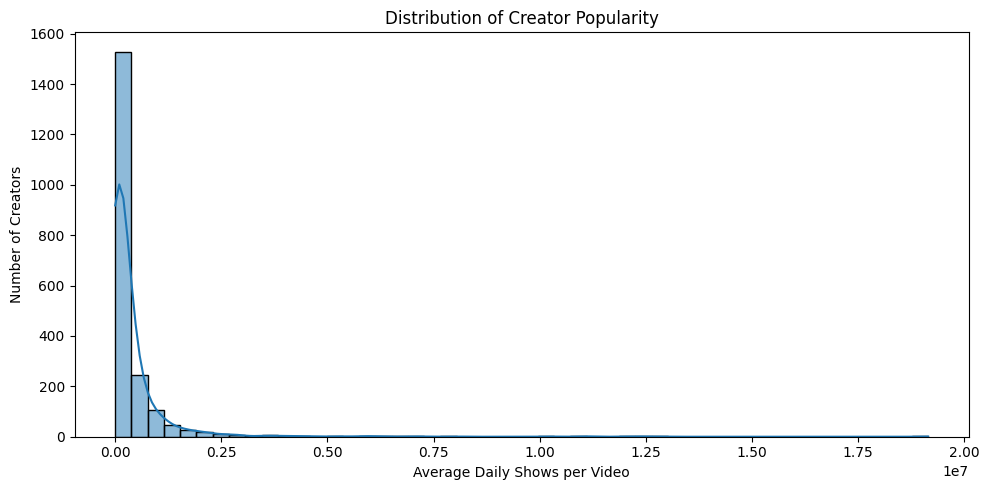

Creator popularity quartiles:


0.25     27650.654412
0.50    114237.505952
0.75    374384.317195
Name: average_video_daily_shows, dtype: float64

In [92]:
# Examine the distribution of creator popularity

plt.figure(figsize=(10, 5))

sns.histplot(
    creator_popularity["average_video_daily_shows"],
    bins=50,
    kde=True
)

plt.title("Distribution of Creator Popularity")
plt.xlabel("Average Daily Shows per Video")
plt.ylabel("Number of Creators")
plt.tight_layout()
plt.show()

print("Creator popularity quartiles:")
display(
    creator_popularity["average_video_daily_shows"]
    .quantile([0.25, 0.50, 0.75])
)

In [93]:
# Classify creators using the 25th percentile popularity threshold

emerging_threshold = creator_popularity[
    "average_video_daily_shows"
].quantile(0.25)

creator_popularity["creator_group"] = np.where(
    creator_popularity["average_video_daily_shows"] <= emerging_threshold,
    "Emerging",
    "Established"
)

print("Emerging creator threshold:", emerging_threshold)

print("\nCreator group distribution:")
display(
    creator_popularity["creator_group"]
    .value_counts()
    .to_frame(name="Number of Creators")
)

print("\nCreator group percentages:")
display(
    (creator_popularity["creator_group"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame(name="Percentage")
)

Emerging creator threshold: 27650.654411764706

Creator group distribution:


,Number of Creators
creator_group,
Established,1515
Emerging,505



Creator group percentages:


,Percentage
creator_group,
Established,75.0
Emerging,25.0


In [94]:
# Attach creator popularity and group labels to the video mapping

video_creator_groups = (
    video_creator_map
    .merge(
        creator_popularity[
            ["author_id", "average_video_daily_shows", "creator_group"]
        ],
        on="author_id",
        how="left"
    )
)

print("Final video-creator mapping created.")
print("\nDimensions:", video_creator_groups.shape)

print("\nMissing creator classifications:",
      video_creator_groups["creator_group"].isna().sum())

print("\nVideo counts by creator group:")
display(
    video_creator_groups["creator_group"]
    .value_counts(dropna=False)
    .to_frame(name="Number of Videos")
)

display(video_creator_groups.head())

Final video-creator mapping created.

Dimensions: (3327, 4)

Missing creator classifications: 12

Video counts by creator group:


,Number of Videos
creator_group,
Established,2760
Emerging,555
NaN,12


,video_id,author_id,average_video_daily_shows,creator_group
0,103,1862,120356.982143,Established
1,109,1853,23561.714286,Emerging
2,120,4450,47238.071429,Established
3,122,888,171880.415179,Established
4,128,2269,488870.392857,Established


In [95]:
# Validate creator classification and future-uploaded videos

post_cutoff_videos = set(
    video_upload_dates.loc[
        video_upload_dates["upload_dt"] > training_cutoff,
        "video_id"
    ]
)

post_cutoff_mapping = video_creator_groups[
    video_creator_groups["video_id"].isin(post_cutoff_videos)
]

print("Videos uploaded after training cutoff:", len(post_cutoff_videos))

print("\nClassification of post-cutoff videos:")
display(
    post_cutoff_mapping["creator_group"]
    .value_counts(dropna=False)
    .to_frame(name="Number of Videos")
)

print(
    "\nTotal unclassified videos:",
    video_creator_groups["creator_group"].isna().sum()
)

print(
    "Unique unclassified creators:",
    video_creator_groups.loc[
        video_creator_groups["creator_group"].isna(),
        "author_id"
    ].nunique()
)

Videos uploaded after training cutoff: 37

Classification of post-cutoff videos:


,Number of Videos
creator_group,
Established,25
NaN,12



Total unclassified videos: 12
Unique unclassified creators: 11


In [96]:
# Summarise creator and video group distributions

creator_group_summary = (
    creator_popularity["creator_group"]
    .value_counts()
    .rename_axis("Creator Group")
    .reset_index(name="Number of Creators")
)

creator_group_summary["Percentage"] = (
    creator_group_summary["Number of Creators"]
    / len(creator_popularity) * 100
).round(2)

video_group_summary = (
    video_creator_groups["creator_group"]
    .value_counts(dropna=False)
    .rename_axis("Creator Group")
    .reset_index(name="Number of Videos")
)

video_group_summary["Percentage"] = (
    video_group_summary["Number of Videos"]
    / len(video_creator_groups) * 100
).round(2)

video_group_summary["Creator Group"] = (
    video_group_summary["Creator Group"].fillna("Unclassified")
)

print("CREATOR-LEVEL DISTRIBUTION")
display(creator_group_summary)

print("\nVIDEO-LEVEL DISTRIBUTION")
display(video_group_summary)

CREATOR-LEVEL DISTRIBUTION


,Creator Group,Number of Creators,Percentage
0,Established,1515,75.0
1,Emerging,505,25.0



VIDEO-LEVEL DISTRIBUTION


,Creator Group,Number of Videos,Percentage
0,Established,2760,82.96
1,Emerging,555,16.68
2,Unclassified,12,0.36


In [97]:
# Check repeated user-video pairs

duplicate_user_video_pairs = small_matrix.duplicated(
    subset=["user_id", "video_id"]
).sum()

unique_user_video_pairs = small_matrix[
    ["user_id", "video_id"]
].drop_duplicates().shape[0]

num_users = small_matrix["user_id"].nunique()
num_videos = small_matrix["video_id"].nunique()

possible_pairs = num_users * num_videos

corrected_density = (
    unique_user_video_pairs / possible_pairs
) * 100

print("Total interaction records:", len(small_matrix))
print("Unique user-video pairs:", unique_user_video_pairs)
print("Repeated user-video pairs:", duplicate_user_video_pairs)
print("Possible user-video pairs:", possible_pairs)

print("\nCorrected interaction matrix density:",
      round(corrected_density, 4), "%")

Total interaction records: 4676570
Unique user-video pairs: 4676570
Repeated user-video pairs: 0
Possible user-video pairs: 4694397

Corrected interaction matrix density: 99.6202 %


In [98]:
# Validate interaction dates

print("Original date column missing:",
      small_matrix["date"].isna().sum())

print("Original time column missing:",
      small_matrix["time"].isna().sum())

print("Original timestamp column missing:",
      small_matrix["timestamp"].isna().sum())

# Convert date into datetime format
small_matrix["interaction_date"] = pd.to_datetime(
    small_matrix["date"].astype("Int64").astype(str),
    format="%Y%m%d",
    errors="coerce"
)

print("\nEarliest interaction date:",
      small_matrix["interaction_date"].min())

print("Latest interaction date:",
      small_matrix["interaction_date"].max())

print("Unique interaction dates:",
      small_matrix["interaction_date"].nunique())

Original date column missing: 181992
Original time column missing: 181992
Original timestamp column missing: 181992

Earliest interaction date: 2020-07-05 00:00:00
Latest interaction date: 2020-09-05 00:00:00
Unique interaction dates: 63


In [99]:
# Validate Unix timestamps against original local time

valid_time_records = small_matrix.dropna(
    subset=["time", "timestamp"]
).copy()

valid_time_records["parsed_time"] = pd.to_datetime(
    valid_time_records["time"],
    errors="coerce"
)

valid_time_records["converted_timestamp"] = (
    pd.to_datetime(
        valid_time_records["timestamp"],
        unit="s",
        utc=True
    )
    .dt.tz_convert("Asia/Shanghai")
    .dt.tz_localize(None)
)

valid_time_records["time_difference_seconds"] = (
    valid_time_records["parsed_time"]
    - valid_time_records["converted_timestamp"]
).dt.total_seconds()

print("Comparable records:", len(valid_time_records))

print(
    "Median absolute difference (seconds):",
    valid_time_records["time_difference_seconds"].abs().median()
)

print(
    "95th percentile absolute difference (seconds):",
    valid_time_records["time_difference_seconds"].abs().quantile(0.95)
)

print(
    "Records differing by more than 1 second:",
    (valid_time_records["time_difference_seconds"].abs() > 1).sum()
)

Comparable records: 4494578
Median absolute difference (seconds): 5.9e-08
95th percentile absolute difference (seconds): 1.13e-07
Records differing by more than 1 second: 0


In [100]:
# Create chronological training and testing datasets

temporal_data = small_matrix.dropna(
    subset=["interaction_date"]
).copy()

training_data = temporal_data[
    temporal_data["interaction_date"] <= pd.Timestamp("2020-08-29")
].copy()

testing_data = temporal_data[
    temporal_data["interaction_date"] >= pd.Timestamp("2020-08-30")
].copy()

print("TRAINING DATA")
print("Records:", len(training_data))
print("Start:", training_data["interaction_date"].min())
print("End:", training_data["interaction_date"].max())

print("\nTESTING DATA")
print("Records:", len(testing_data))
print("Start:", testing_data["interaction_date"].min())
print("End:", testing_data["interaction_date"].max())

print("\nMissing-date records excluded from temporal split:",
      small_matrix["interaction_date"].isna().sum())

print("\nTotal records accounted for:",
      len(training_data) + len(testing_data)
      + small_matrix["interaction_date"].isna().sum())

TRAINING DATA
Records: 4387382
Start: 2020-07-05 00:00:00
End: 2020-08-29 00:00:00

TESTING DATA
Records: 107196
Start: 2020-08-30 00:00:00
End: 2020-09-05 00:00:00

Missing-date records excluded from temporal split: 181992

Total records accounted for: 4676570


In [101]:
# Validate chronological split boundaries

train_max_date = training_data["interaction_date"].max()
test_min_date = testing_data["interaction_date"].min()

print("Latest training interaction:", train_max_date)
print("Earliest testing interaction:", test_min_date)

print("\nTraining contains dates after cutoff:",
      (training_data["interaction_date"] > pd.Timestamp("2020-08-29")).any())

print("Testing contains dates before test start:",
      (testing_data["interaction_date"] < pd.Timestamp("2020-08-30")).any())

print("Chronological separation valid:",
      train_max_date < test_min_date)

Latest training interaction: 2020-08-29 00:00:00
Earliest testing interaction: 2020-08-30 00:00:00

Training contains dates after cutoff: False
Testing contains dates before test start: False
Chronological separation valid: True


In [102]:
# Load video category metadata

item_categories = pd.read_csv(
    os.path.join(data_path, "item_categories.csv")
)

print("Item category metadata loaded successfully!")
print("\nDataset dimensions:", item_categories.shape)

print("\nColumn names:")
print(item_categories.columns.tolist())

print("\nFirst five records:")
display(item_categories.head())

Item category metadata loaded successfully!

Dataset dimensions: (10728, 2)

Column names:
['video_id', 'feat']

First five records:


,video_id,feat
0,0,[8]
1,1,"[27, 9]"
2,2,[9]
3,3,[26]
4,4,[5]


In [103]:
# Inspect category feature structure

print("Missing video IDs:", item_categories["video_id"].isna().sum())
print("Missing feature values:", item_categories["feat"].isna().sum())

print("\nUnique videos:", item_categories["video_id"].nunique())
print("Duplicate video IDs:",
      item_categories["video_id"].duplicated().sum())

print("\nSample feature values:")
for value in item_categories["feat"].head(10):
    print(value, "| Type:", type(value).__name__)

Missing video IDs: 0
Missing feature values: 0

Unique videos: 10728
Duplicate video IDs: 0

Sample feature values:
[8] | Type: str
[27, 9] | Type: str
[9] | Type: str
[26] | Type: str
[5] | Type: str
[6] | Type: str
[19] | Type: str
[8] | Type: str
[12] | Type: str
[11] | Type: str


In [104]:
import ast

# Convert string representations into actual Python lists
item_categories["category_ids"] = item_categories["feat"].apply(
    ast.literal_eval
)

print("Category values parsed successfully!")

print("\nSample parsed values:")
display(
    item_categories[["video_id", "feat", "category_ids"]].head(10)
)

print("\nData type after parsing:",
      type(item_categories["category_ids"].iloc[0]).__name__)

print("\nNumber of videos with empty category lists:",
      (item_categories["category_ids"].apply(len) == 0).sum())

Category values parsed successfully!

Sample parsed values:


,video_id,feat,category_ids
0,0,[8],[8]
1,1,"[27, 9]","[27, 9]"
2,2,[9],[9]
3,3,[26],[26]
4,4,[5],[5]
5,5,[6],[6]
6,6,[19],[19]
7,7,[8],[8]
8,8,[12],[12]
9,9,[11],[11]



Data type after parsing: list

Number of videos with empty category lists: 0


In [105]:
from collections import Counter

# Count category occurrences across videos
category_counts = Counter(
    category
    for categories in item_categories["category_ids"]
    for category in categories
)

category_distribution = pd.DataFrame(
    category_counts.items(),
    columns=["category_id", "video_count"]
).sort_values(
    "video_count",
    ascending=False
).reset_index(drop=True)

print("Total distinct categories:", len(category_distribution))
print("Total category assignments:", category_distribution["video_count"].sum())

print("\nTop 15 most frequent categories:")
display(category_distribution.head(15))

print("\nCategory frequency summary:")
display(category_distribution["video_count"].describe())

Total distinct categories: 31
Total category assignments: 12693

Top 15 most frequent categories:


,category_id,video_count
0,11,2027
1,28,1360
2,8,1112
3,5,964
4,6,912
5,9,696
6,19,686
7,12,534
8,7,503
9,26,490



Category frequency summary:


count      31.000000
mean      409.451613
std       465.588720
min         5.000000
25%        51.000000
50%       245.000000
75%       518.500000
max      2027.000000
Name: video_count, dtype: float64

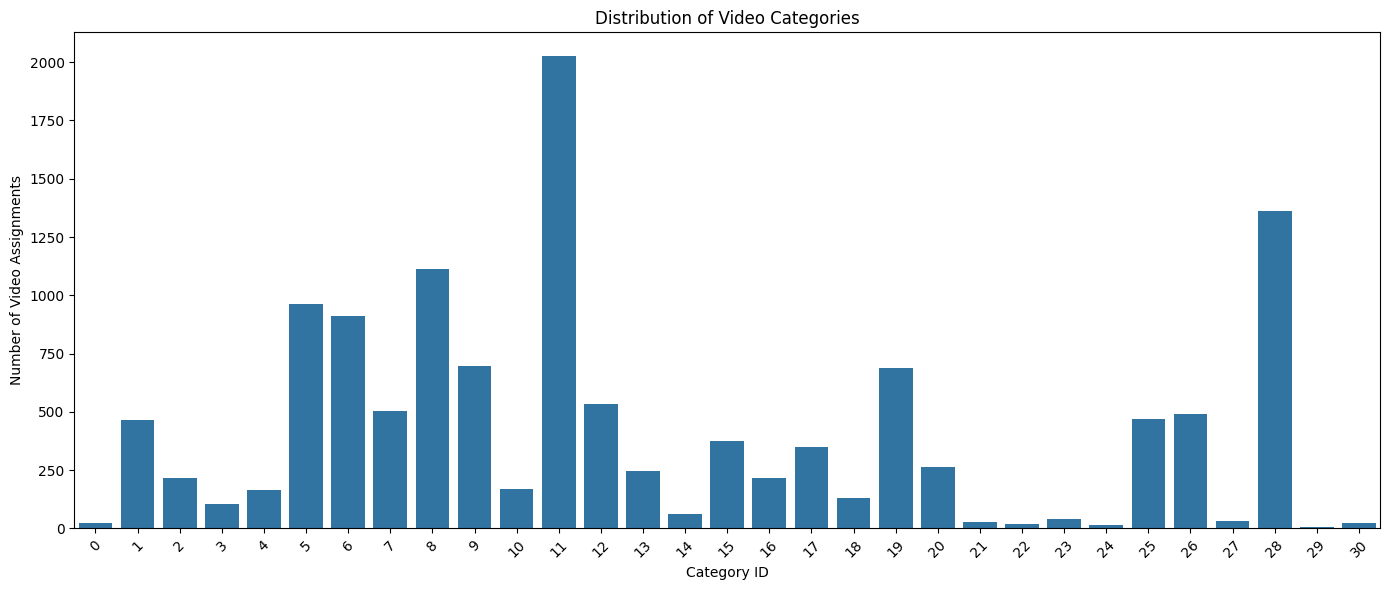

In [106]:
# Visualise category frequency distribution

plt.figure(figsize=(14, 6))

sns.barplot(
    data=category_distribution,
    x="category_id",
    y="video_count"
)

plt.title("Distribution of Video Categories")
plt.xlabel("Category ID")
plt.ylabel("Number of Video Assignments")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [107]:
# Calculate number of categories assigned to each video

item_categories["category_count"] = (
    item_categories["category_ids"].apply(len)
)

print("Category count distribution per video:")
display(item_categories["category_count"].value_counts().sort_index())

print("\nSummary statistics:")
display(item_categories["category_count"].describe())

print("\nVideos with multiple categories:",
      (item_categories["category_count"] > 1).sum())

print("Videos with only one category:",
      (item_categories["category_count"] == 1).sum())

Category count distribution per video:


category_count
1    8970
2    1562
3     185
4      11
Name: count, dtype: int64


Summary statistics:


count    10728.000000
mean         1.183166
std          0.436205
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: category_count, dtype: float64


Videos with multiple categories: 1758
Videos with only one category: 8970


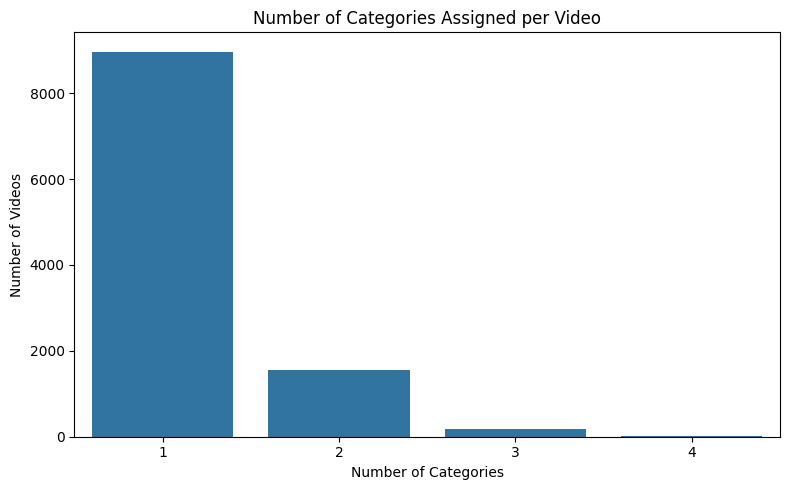

In [108]:
# Visualise number of categories assigned per video

category_count_distribution = (
    item_categories["category_count"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_count_distribution.index,
    y=category_count_distribution.values
)

plt.title("Number of Categories Assigned per Video")
plt.xlabel("Number of Categories")
plt.ylabel("Number of Videos")

plt.tight_layout()
plt.show()

In [110]:
# Retry loading caption-category metadata with Python parser

caption_file = os.path.join(
    data_path,
    "kuairec_caption_category.csv"
)

caption_categories = pd.read_csv(
    caption_file,
    engine="python"
)

print("Caption-category metadata loaded successfully!")
print("\nDataset dimensions:", caption_categories.shape)

print("\nColumn names:")
print(caption_categories.columns.tolist())

print("\nFirst five records:")
display(caption_categories.head())

Caption-category metadata loaded successfully!

Dataset dimensions: (10732, 10)

Column names:
['video_id', 'manual_cover_text', 'caption', 'topic_tag', 'first_level_category_id', 'first_level_category_name', 'second_level_category_id', 'second_level_category_name', 'third_level_category_id', 'third_level_category_name']

First five records:


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
0,0,UNKNOWN,精神小伙路难走 程哥你狗粮慢点撒,[],8.0,颜值,673.0,颜值随拍,-124.0,UNKNOWN
1,1,UNKNOWN,NaN,[],27.0,高新数码,-124.0,UNKNOWN,-124.0,UNKNOWN
2,2,UNKNOWN,晚饭后，运动一下！,[],9.0,喜剧,727.0,搞笑互动,-124.0,UNKNOWN
3,3,UNKNOWN,我平淡无奇，惊艳不了时光，温柔不了岁月，我只想漫无目的的走走，努力发笔小财，给自己买花 自己长大.,[],26.0,摄影,686.0,主题摄影,2434.0,景物摄影
4,4,五爱街最美美女 一天1q,#搞笑 #感谢快手我要上热门 #五爱市场 这真是完美搭配啊！,"[五爱市场,感谢快手我要上热门,搞笑]",5.0,时尚,737.0,营销售卖,2596.0,女装


In [111]:
# Inspect missing values in caption-category metadata

print("Total records:", len(caption_categories))

print("\nMissing values per column:")
display(
    caption_categories.isna().sum().to_frame(
        name="missing_count"
    )
)

print("\nMissing percentage per column:")
display(
    (
        caption_categories.isna().mean() * 100
    ).round(2).to_frame(
        name="missing_percentage"
    )
)

print("\nUnique video IDs:", caption_categories["video_id"].nunique())

print("Duplicate video IDs:",
      caption_categories["video_id"].duplicated().sum())


Total records: 10732

Missing values per column:


,missing_count
video_id,1
manual_cover_text,0
caption,1355
topic_tag,4
first_level_category_id,4
first_level_category_name,4
second_level_category_id,4
second_level_category_name,4
third_level_category_id,8
third_level_category_name,8



Missing percentage per column:


,missing_percentage
video_id,0.01
manual_cover_text,0.00
caption,12.63
topic_tag,0.04
first_level_category_id,0.04
first_level_category_name,0.04
second_level_category_id,0.04
second_level_category_name,0.04
third_level_category_id,0.07
third_level_category_name,0.07



Unique video IDs: 10730
Duplicate video IDs: 1


In [112]:
# Inspect records with missing video IDs

missing_video_records = caption_categories[
    caption_categories["video_id"].isna()
]

print("Records with missing video IDs:")
display(missing_video_records)

# Inspect duplicate video IDs

duplicate_video_records = caption_categories[
    caption_categories["video_id"].notna()
    & caption_categories["video_id"].duplicated(keep=False)
].sort_values("video_id")

print("\nRecords with duplicate video IDs:")
display(duplicate_video_records)

print("\nNumber of duplicate records:",
      len(duplicate_video_records))

Records with missing video IDs:


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
5913,NaN,[],34,其他,418.0,生活泛拍,-124.0,UNKNOWN,NaN,None



Records with duplicate video IDs:


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
1615,,"[井柏然,宋威龙,张公案]",6,明星娱乐,667.0,娱乐八卦,2377.0,明星八卦,NaN,None
6335,,[],-124,UNKNOWN,-124.0,UNKNOWN,-124.0,UNKNOWN,NaN,None



Number of duplicate records: 2


In [113]:
# Inspect blank and missing video IDs

print("Missing video IDs:", caption_categories["video_id"].isna().sum())

blank_video_ids = (
    caption_categories["video_id"]
    .astype("string")
    .str.strip()
    .eq("")
)

print("Blank video IDs:", blank_video_ids.sum())

print("\nRecords with blank video IDs:")
display(caption_categories[blank_video_ids])

Missing video IDs: 1
Blank video IDs: 2

Records with blank video IDs:


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
1615,,"[井柏然,宋威龙,张公案]",6,明星娱乐,667.0,娱乐八卦,2377.0,明星八卦,NaN,None
6335,,[],-124,UNKNOWN,-124.0,UNKNOWN,-124.0,UNKNOWN,NaN,None


In [114]:
# Create a copy containing only records with valid video IDs

caption_categories_clean = caption_categories.copy()

caption_categories_clean["video_id"] = (
    caption_categories_clean["video_id"]
    .astype("string")
    .str.strip()
)

caption_categories_clean = caption_categories_clean[
    caption_categories_clean["video_id"].notna()
    & (caption_categories_clean["video_id"] != "")
].copy()

caption_categories_clean["video_id"] = (
    pd.to_numeric(
        caption_categories_clean["video_id"],
        errors="coerce"
    )
)

caption_categories_clean = caption_categories_clean.dropna(
    subset=["video_id"]
)

caption_categories_clean["video_id"] = (
    caption_categories_clean["video_id"].astype("int64")
)

print("Original records:", len(caption_categories))
print("Records with valid video IDs:", len(caption_categories_clean))
print("Records excluded:", len(caption_categories) - len(caption_categories_clean))

print("Remaining duplicate video IDs:",
      caption_categories_clean["video_id"].duplicated().sum())

Original records: 10732
Records with valid video IDs: 10728
Records excluded: 4
Remaining duplicate video IDs: 0


In [115]:
# Identify records excluded during cleaning

excluded_caption_records = caption_categories[
    ~caption_categories.index.isin(
        caption_categories_clean.index
    )
]

print("Excluded records:")
display(excluded_caption_records)

print("\nOriginal video ID values:")
display(excluded_caption_records["video_id"])

Excluded records:


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
1379,！”,[],6,明星娱乐,-124.0,UNKNOWN,-124.0,UNKNOWN,NaN,None
1615,,"[井柏然,宋威龙,张公案]",6,明星娱乐,667.0,娱乐八卦,2377.0,明星八卦,NaN,None
5913,NaN,[],34,其他,418.0,生活泛拍,-124.0,UNKNOWN,NaN,None
6335,,[],-124,UNKNOWN,-124.0,UNKNOWN,-124.0,UNKNOWN,NaN,None



Original video ID values:


1379     ！”
1615       
5913    NaN
6335       
Name: video_id, dtype: object

In [116]:
# Analyse missing values in cleaned caption metadata

print("Cleaned metadata shape:", caption_categories_clean.shape)

print("\nMissing values:")
display(
    caption_categories_clean.isna().sum().to_frame(
        name="missing_count"
    )
)

print("\nCaption availability:")
print(
    "Available captions:",
    caption_categories_clean["caption"].notna().sum()
)

print(
    "Missing captions:",
    caption_categories_clean["caption"].isna().sum()
)

print("\nFirst-level category availability:")
print(
    caption_categories_clean["first_level_category_name"]
    .notna()
    .sum()
)

print("\nSecond-level category availability:")
print(
    caption_categories_clean["second_level_category_name"]
    .notna()
    .sum()
)

print("\nThird-level category availability:")
print(
    caption_categories_clean["third_level_category_name"]
    .notna()
    .sum()
)

Cleaned metadata shape: (10728, 10)

Missing values:


,missing_count
video_id,0
manual_cover_text,0
caption,1355
topic_tag,4
first_level_category_id,4
first_level_category_name,4
second_level_category_id,4
second_level_category_name,4
third_level_category_id,4
third_level_category_name,4



Caption availability:
Available captions: 9373
Missing captions: 1355

First-level category availability:
10724

Second-level category availability:
10724

Third-level category availability:
10724


In [117]:
# Compare video coverage across category metadata sources

item_category_videos = set(item_categories["video_id"])
caption_category_videos = set(caption_categories_clean["video_id"])
interaction_video_ids = set(small_matrix["video_id"].unique())

print("ITEM CATEGORY METADATA")
print("Unique videos:", len(item_category_videos))

print("\nCAPTION CATEGORY METADATA")
print("Unique videos:", len(caption_category_videos))

print("\nINTERACTION DATASET")
print("Unique videos:", len(interaction_video_ids))

print("\nCOMPARISON")
print(
    "Videos common to both metadata sources:",
    len(item_category_videos & caption_category_videos)
)

print(
    "Videos only in item_categories:",
    len(item_category_videos - caption_category_videos)
)

print(
    "Videos only in caption_categories:",
    len(caption_category_videos - item_category_videos)
)

print(
    "Experimental videos covered by both sources:",
    len(
        interaction_video_ids
        & item_category_videos
        & caption_category_videos
    )
)

ITEM CATEGORY METADATA
Unique videos: 10728

CAPTION CATEGORY METADATA
Unique videos: 10728

INTERACTION DATASET
Unique videos: 3327

COMPARISON
Videos common to both metadata sources: 10728
Videos only in item_categories: 0
Videos only in caption_categories: 0
Experimental videos covered by both sources: 3327


In [118]:
# Create combined video metadata for experimental videos

experimental_video_metadata = (
    item_categories[
        ["video_id", "category_ids", "category_count"]
    ]
    .merge(
        caption_categories_clean,
        on="video_id",
        how="inner",
        validate="one_to_one"
    )
)

experimental_video_metadata = (
    experimental_video_metadata[
        experimental_video_metadata["video_id"].isin(
            interaction_video_ids
        )
    ]
    .reset_index(drop=True)
)

print("Experimental video metadata shape:",
      experimental_video_metadata.shape)

print("\nUnique videos:",
      experimental_video_metadata["video_id"].nunique())

print("\nDuplicate video IDs:",
      experimental_video_metadata["video_id"].duplicated().sum())

print("\nSample records:")
display(
    experimental_video_metadata[
        [
            "video_id",
            "category_ids",
            "first_level_category_name",
            "second_level_category_name",
            "third_level_category_name",
            "caption"
        ]
    ].head()
)

Experimental video metadata shape: (3327, 12)

Unique videos: 3327

Duplicate video IDs: 0

Sample records:


,video_id,category_ids,first_level_category_name,second_level_category_name,third_level_category_name,caption
0,103,[12],美食,美食教程,菜肴,用半张饺子皮就能包馄饨简单漂亮，又省事，喜欢赶快动手试试吧。#快手九周年 #爱官方爱热门支持...
1,109,"[18, 5]",汽车,玩车,机车族,今天不教你们压弯过几天 #中国摩博会 #ClMA骑士
2,120,[9],喜剧,UNKNOWN,UNKNOWN,哈哈哈跑出一股偷菜贼的感觉
3,122,[9],喜剧,搞笑配音,UNKNOWN,#搞笑 #搞笑配音
4,128,"[11, 12, 9]",美食,美食日常,美食分享,NaN


In [119]:
# Check metadata completeness for experimental videos

metadata_columns = [
    "category_ids",
    "first_level_category_name",
    "second_level_category_name",
    "third_level_category_name",
    "caption",
    "topic_tag"
]

print("Experimental metadata completeness:")
display(
    experimental_video_metadata[metadata_columns]
    .isna()
    .sum()
    .to_frame(name="missing_count")
)

print("\nCaption availability:")
print(
    "Available:",
    experimental_video_metadata["caption"].notna().sum()
)

print(
    "Missing:",
    experimental_video_metadata["caption"].isna().sum()
)

print("\nFirst-level category availability:")
print(
    experimental_video_metadata["first_level_category_name"]
    .notna()
    .sum()
)

Experimental metadata completeness:


,missing_count
category_ids,0
first_level_category_name,2
second_level_category_name,2
third_level_category_name,2
caption,158
topic_tag,2



Caption availability:
Available: 3169
Missing: 158

First-level category availability:
3325


In [120]:
# Prepare research-ready interaction dataset

research_interactions = small_matrix.copy()

research_interactions["interaction_date"] = pd.to_datetime(
    research_interactions["interaction_date"],
    errors="coerce"
)

print("Research interaction dataset:", research_interactions.shape)

print("\nUnique users:",
      research_interactions["user_id"].nunique())

print("Unique videos:",
      research_interactions["video_id"].nunique())

print("Missing interaction dates:",
      research_interactions["interaction_date"].isna().sum())

print("\nTraining records:", len(training_data))
print("Testing records:", len(testing_data))

Research interaction dataset: (4676570, 9)

Unique users: 1411
Unique videos: 3327
Missing interaction dates: 181992

Training records: 4387382
Testing records: 107196


In [121]:
# Prepare final reusable research artifacts

research_artifacts = {
    "interactions": research_interactions,
    "training_interactions": training_data,
    "testing_interactions": testing_data,
    "video_creator_map": video_creator_map,
    "creator_popularity": creator_popularity,
    "video_creator_groups": video_creator_groups,
    "video_metadata": experimental_video_metadata,
    "category_distribution": category_distribution
}

print("Research artifacts prepared:\n")

for artifact_name, artifact_data in research_artifacts.items():
    print(
        f"{artifact_name}: "
        f"{artifact_data.shape[0]} rows × "
        f"{artifact_data.shape[1]} columns"
    )

Research artifacts prepared:

interactions: 4676570 rows × 9 columns
training_interactions: 4387382 rows × 9 columns
testing_interactions: 107196 rows × 9 columns
video_creator_map: 3327 rows × 2 columns
creator_popularity: 2020 rows × 5 columns
video_creator_groups: 3327 rows × 4 columns
video_metadata: 3327 rows × 12 columns
category_distribution: 31 rows × 2 columns


In [122]:
# Create directory for processed research datasets

processed_path = "../processed_data"
os.makedirs(processed_path, exist_ok=True)

# Save all research artifacts
for artifact_name, artifact_data in research_artifacts.items():
    file_path = os.path.join(
        processed_path,
        f"{artifact_name}.csv"
    )

    artifact_data.to_csv(file_path, index=False)

    print(f"Saved: {file_path}")

print("\nAll research artifacts saved successfully!")

Saved: ../processed_data\interactions.csv
Saved: ../processed_data\training_interactions.csv
Saved: ../processed_data\testing_interactions.csv
Saved: ../processed_data\video_creator_map.csv
Saved: ../processed_data\creator_popularity.csv
Saved: ../processed_data\video_creator_groups.csv
Saved: ../processed_data\video_metadata.csv
Saved: ../processed_data\category_distribution.csv

All research artifacts saved successfully!


In [123]:
# Verify saved research artifacts

print("VERIFYING SAVED FILES\n")

for artifact_name, original_data in research_artifacts.items():

    file_path = os.path.join(
        processed_path,
        f"{artifact_name}.csv"
    )

    saved_data = pd.read_csv(file_path)

    print(f"{artifact_name}:")
    print("  File exists:", os.path.exists(file_path))
    print("  Original shape:", original_data.shape)
    print("  Saved shape:", saved_data.shape)
    print("  Shape matches:", original_data.shape == saved_data.shape)
    print()

VERIFYING SAVED FILES

interactions:
  File exists: True
  Original shape: (4676570, 9)
  Saved shape: (4676570, 9)
  Shape matches: True

training_interactions:
  File exists: True
  Original shape: (4387382, 9)
  Saved shape: (4387382, 9)
  Shape matches: True

testing_interactions:
  File exists: True
  Original shape: (107196, 9)
  Saved shape: (107196, 9)
  Shape matches: True

video_creator_map:
  File exists: True
  Original shape: (3327, 2)
  Saved shape: (3327, 2)
  Shape matches: True

creator_popularity:
  File exists: True
  Original shape: (2020, 5)
  Saved shape: (2020, 5)
  Shape matches: True

video_creator_groups:
  File exists: True
  Original shape: (3327, 4)
  Saved shape: (3327, 4)
  Shape matches: True

video_metadata:
  File exists: True
  Original shape: (3327, 12)
  Saved shape: (3327, 12)
  Shape matches: True

category_distribution:
  File exists: True
  Original shape: (31, 2)
  Saved shape: (31, 2)
  Shape matches: True




# Notebook 01: Data Exploration and Preprocessing

## 1. Objective

The objective of this notebook is to explore, validate, and prepare the KuaiRec dataset for the proposed research, **Spotlight: Interest-Constrained Recommendation for Emerging Creators**.

This notebook establishes the dataset characteristics, interaction patterns, creator popularity classification, content-category information, and chronological evaluation split required for subsequent experiments.

## 2. Dataset Overview

The primary interaction dataset (`small_matrix.csv`) contains:

| Metric | Value |
|---|---:|
| Unique users | 1,411 |
| Unique videos | 3,327 |
| Total interactions | 4,676,570 |
| Possible user-video pairs | 4,694,397 |
| Interaction matrix density | 99.62% |
| Repeated user-video pairs | 0 |

The interaction matrix is nearly fully observed, making it important to consider dataset density when interpreting offline recommendation results.

Additional metadata was obtained from `item_daily_features.csv`, `item_categories.csv`, and `kuairec_caption_category.csv`.

## 3. Data Quality and Interaction Analysis

The following checks were performed:

- Dataset dimensions, column names, and data types.
- Missing values and exact duplicate records.
- Unique user and video counts.
- Interaction frequency per user and video.
- Distribution of play duration, video duration, and watch ratio.
- Uniqueness of user-video interaction pairs.

The interaction metrics showed highly skewed distributions. Extreme values were retained rather than removed without sufficient evidence.

The interaction dataset contains 181,992 records with missing date, time, and timestamp information. These records were retained in the master dataset but excluded from chronological evaluation.

## 4. Video and Creator Metadata

The `item_daily_features.csv` dataset contains 343,341 daily metadata records and 58 columns.

The analysis established:

- 3,327 experimental videos were covered by the video metadata.
- 2,031 distinct creators were associated with the experimental video catalogue.
- Creator IDs were consistent across metadata records.
- Historical popularity was calculated using daily `show_cnt` observations up to 29 August 2020.
- Video observation coverage was examined to assess the reliability of historical popularity estimates.

### Creator Popularity Classification

Creators were classified using their average historical daily video popularity.

The first quartile of creator popularity was used as the classification threshold.

| Creator group | Number | Percentage |
|---|---:|---:|
| Emerging | 505 | 25% |
| Established | 1,515 | 75% |
| Total classified | 2,020 | 100% |

Emerging creators represent the bottom quartile of historically classifiable creators in this experimental catalogue. This classification does not necessarily indicate that a creator is newly registered.

Creators without sufficient historical popularity evidence were left unclassified rather than assigned an arbitrary group.

## 5. Content Category Analysis

Two category metadata sources were examined:

1. `item_categories.csv`
2. `kuairec_caption_category.csv`

### Numerical Category Metadata

The numerical category metadata contains:

- 10,728 videos.
- 31 distinct category IDs.
- 12,693 total category assignments.
- Between 1 and 4 category assignments per video.

| Categories per video | Number of videos |
|---|---:|
| 1 | 8,970 |
| 2 | 1,562 |
| 3 | 185 |
| 4 | 11 |

The category distribution was highly imbalanced.

### Hierarchical Category Metadata

The caption-category metadata provides:

- First-level category IDs and names.
- Second-level category IDs and names.
- Third-level category IDs and names.
- Video captions.
- Topic tags.
- Manual cover text.

Four records without valid video identifiers were excluded from the cleaned metadata.

Among the 10,728 valid records, 1,355 captions were missing.

### Metadata Coverage

Both category metadata sources covered exactly the same 10,728-video catalogue.

All 3,327 experimental videos were present in both sources.

Numerical category IDs were available for every experimental video, while 3,169 videos had captions.

**Research decision:** Numerical category IDs will serve as the primary content representation for the interest model. Hierarchical category names will support interpretation, while captions and topic tags will remain supplementary information.

Multi-category assignments will be preserved.

## 6. Chronological Training and Testing Split

A chronological split was established to simulate learning from historical interactions and evaluating on subsequent interactions.

| Dataset | Date range | Interactions |
|---|---|---:|
| Training | 5 July – 29 August 2020 | 4,387,382 |
| Testing | 30 August – 5 September 2020 | 107,196 |
| Missing-date records | Excluded from temporal split | 181,992 |

The original timestamps were validated against the local time representation after conversion from UTC to Asia/Shanghai.

The chronological boundary was also programmatically validated to ensure that no future interactions entered the training dataset.

This split will remain fixed across subsequent experimental notebooks.

## 7. Research Artifacts Saved

The following processed datasets were generated and verified:

| File | Description |
|---|---|
| `interactions.csv` | Complete interaction dataset |
| `training_interactions.csv` | Chronological training interactions |
| `testing_interactions.csv` | Chronological testing interactions |
| `video_creator_map.csv` | Video-to-creator mapping |
| `creator_popularity.csv` | Historical creator popularity metrics |
| `video_creator_groups.csv` | Creator group assignments |
| `video_metadata.csv` | Combined experimental video metadata |
| `category_distribution.csv` | Numerical category frequencies |

All eight files were successfully saved and read back with matching dataframe dimensions.

## 8. Key Research Findings

1. The experimental interaction matrix has a density of 99.62%, which is an important limitation when generalising offline recommendation performance to sparse real-world environments.
2. Creator popularity is highly unequal, motivating an investigation of creator-level exposure distribution.
3. The bottom quartile of classifiable creators provides an operational definition of the Emerging creator group.
4. Numerical category features provide complete coverage of the experimental video catalogue.
5. The category distribution is imbalanced, and multi-category video assignments must be preserved.
6. A fixed chronological split provides a consistent evaluation foundation for subsequent experiments.

## 9. Limitations and Considerations

- The high interaction density of the small matrix may not represent real-world recommendation environments.
- Recommendation-list exposure is an offline proxy and does not represent actual platform impressions or views.
- Creator classification depends on the selected historical popularity measure and observation period.
- Some videos have missing captions or incomplete hierarchical category labels.
- The analysis does not establish causal effects on actual creator growth or platform exposure.

These limitations will be considered when interpreting experimental results.

## 10. Conclusion

This notebook established the data foundation for Spotlight by validating interaction records, examining creator popularity, analysing content categories, and creating a chronological training/testing split.

The processed datasets are ready for use in subsequent experiments.

**Next Notebook:** Notebook 02 – Baseline Recommender

**Remaining Notebooks:** 7
